# Antigen expression and co-detection

## Imports


In [2]:
from __future__ import annotations
from importlib.metadata import PackageNotFoundError, version
from itertools import combinations
from math import comb
from pathlib import Path
from cap.figures import (
    configure_figure_style,
    save_figure,
    save_umap_figure,
)
from cap.paths import get_paths
from cap.provenance import (
    sha256_file,
    validate_frozen_inputs,
    write_run_provenance,
)

In [3]:
import argparse
import gc
import hashlib
import itertools
import json


In [4]:
import logging
import os
import platform
import sys


In [5]:
import shutil
import subprocess

# Discover R from PATH or the installation named by R_HOME before importing rpy2.
r_candidates = [shutil.which("R"), shutil.which("R.exe")]
r_home_env = os.environ.get("R_HOME")
if r_home_env:
    r_home_path = Path(r_home_env).expanduser()
    r_candidates.extend(
        str(candidate)
        for candidate in (
            r_home_path / "bin" / "R.exe",
            r_home_path / "bin" / "x64" / "R.exe",
            r_home_path / "bin" / "R",
            r_home_path / "bin" / "x64" / "R",
        )
    )
r_executable = next(
    (candidate for candidate in r_candidates if candidate and Path(candidate).is_file()),
    None,
)
if r_executable is None:
    raise RuntimeError(
        "R was not found. Add R to PATH or set R_HOME to the R installation directory."
    )

r_home_env = os.environ.get("R_HOME")
if r_home_env and Path(r_home_env).expanduser().is_dir():
    os.environ["R_HOME"] = str(Path(r_home_env).expanduser().resolve())
elif os.name == "nt":
    r_executable_path = Path(r_executable).resolve()
    r_home_path = (
        r_executable_path.parent.parent.parent
        if r_executable_path.parent.name.lower() == "x64"
        else r_executable_path.parent.parent
    )
    os.environ["R_HOME"] = str(r_home_path)
else:
    os.environ["R_HOME"] = subprocess.check_output(
        [r_executable, "RHOME"], text=True
    ).strip()
os.environ["RPY2_CFFI_MODE"] = "ABI"


In [6]:
from anndata.io import read_elem
from matplotlib import colormaps
from matplotlib.colors import to_hex
from matplotlib.lines import Line2D
from scipy import sparse


In [7]:
from scipy import stats
from scipy.stats import binomtest, hypergeom, mannwhitneyu
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.multitest import multipletests
import h5py


In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp


In [9]:
import seaborn as sns
from rpy2.robjects import numpy2ri
from rpy2.robjects.conversion import localconverter
import rpy2.rinterface_lib.callbacks as rcb
import rpy2.robjects as ro


In [10]:
import session_info


## Paths


In [11]:
# CAP_DATA_ROOT and CAP_RUN_ID are read from the environment or repository .env.
paths = get_paths()
paths.validate_base_inputs()
validate_frozen_inputs(paths)
project = paths.root


In [12]:
analysis_dir = paths.run_root


In [13]:
import logging
logging.getLogger("fontTools.subset").setLevel(logging.WARNING)


In [14]:
data_dir = paths.data_root


In [15]:
annotation_dir = paths.stage_dir("02_cell_annotation")
paths.require_dir(annotation_dir, "02_cell_annotation stage")


WindowsPath('D:/IdeaProjects/CAP_Submission/CAP_Data/runs/preprocessing_test_003/02_cell_annotation')

In [16]:
run_dir = paths.ensure_stage("03c_antigen_coexpression")


In [17]:
programme_dir = paths.stage_dir("03b_meta_programmes")
paths.require_dir(programme_dir, "03b_meta_programmes stage")


WindowsPath('D:/IdeaProjects/CAP_Submission/CAP_Data/runs/preprocessing_test_003/03b_meta_programmes')

In [18]:
adata_file = programme_dir / "h5ad" / "epithelial_meta_programmes.h5ad"


In [19]:
reference_dir = paths.frozen_dir


In [20]:
notebook_dir = paths.root / "notebooks"


Antigen expression and co-detection are analysed in the primary epithelial cohort. Positivity and co-detection are defined from raw
UMI counts. ALRA is used only to visualise ROR1 on the epithelial
embedding. Donors, rather than cells, are the unit of biological
replication.

In [21]:
np.random.seed(0)


In [22]:
sc.settings.verbosity = 1


In [23]:
rcb.logger.setLevel(logging.ERROR)


In [24]:
configure_figure_style()


In [25]:
# Figure typography and export settings are configured centrally by cap.figures.


In [26]:
target_genes = ["ROR1", "ROR2", "EGFR", "ERBB2", "EPCAM"]


In [27]:
antigen_pairs = [("ROR1", "EGFR"), ("EPCAM", "ERBB2")]


In [28]:
conditions = ["N", "ER+", "HER2+", "TN"]


In [29]:
tumour_conditions = ["TN", "HER2+", "ER+"]


In [30]:
primary_min_umi = 1


In [31]:
min_umi_sweep = [1, 2, 3]


In [32]:
min_double_positive_cells = 5


In [33]:
fig_dir = run_dir / "figures"


In [34]:
df_dir = run_dir / "tables"


In [35]:
save_dir = run_dir / "h5ad"


In [36]:
identity_counts_file = (
    annotation_dir / "tables" / "epithelial_identity_scope_counts_by_library.csv"
)
paths.require_file(adata_file, "03b meta-programmes H5AD")
paths.require_file(identity_counts_file, "02 epithelial identity scope-count table")
if any(run_dir.iterdir()):
    raise FileExistsError(
        f"{run_dir} is not empty. Set a fresh CAP_RUN_ID for a new immutable run."
    )


In [37]:
for directory in (fig_dir, df_dir, save_dir):
    directory.mkdir(parents=True, exist_ok=True)

write_run_provenance(paths, run_dir)

input_checksums = {
    "03b_meta_programmes/h5ad/epithelial_meta_programmes.h5ad": sha256_file(adata_file),
    "02_cell_annotation/tables/epithelial_identity_scope_counts_by_library.csv": sha256_file(
        identity_counts_file
    ),
    "gene_policy.json": sha256_file(paths.frozen_dir / "gene_policy.json"),
    "frozen_inputs.json": sha256_file(paths.manifest_dir / "frozen_inputs.json"),
}
(run_dir / "input_checksums.json").write_text(
    json.dumps(input_checksums, indent=2) + "\n",
    encoding="utf-8",
)


462

In [38]:
sc.settings.figdir = fig_dir


In [39]:
# Figure typography and export settings are configured centrally by cap.figures.


In [40]:
def rel(path):
    path = Path(path).resolve()
    for base, label in ((paths.root, Path(".")), (paths.data_root, Path("CAP_DATA_ROOT"))):
        try:
            return label / path.relative_to(base)
        except ValueError:
            continue
    return Path("<external>") / path.name


In [41]:
policy_file = reference_dir / "gene_policy.json"


In [42]:
policy_sha256 = "c4213d53e2d3209312e7781c73ed20f660e0f256042956742693c0e0375926a6"


In [43]:
def load_gene_policy(path=policy_file):
    path = Path(path)
    payload = path.read_bytes()
    digest = hashlib.sha256(payload).hexdigest()
    if digest != policy_sha256:
        raise ValueError(
            "Gene-policy checksum differs from the reviewed source snapshot"
        )
    policy = json.loads(payload)
    policy["sha256"] = digest
    return policy


In [44]:
gene_policy = load_gene_policy()


## Load

In [45]:
epi = sc.read_h5ad(adata_file)


In [46]:
assert "cohort_selection" in epi.uns, "Input lacks the cohort-selection record; use the output from the updated upstream notebook."


In [47]:
cohort_selection = epi.uns["cohort_selection"]


In [48]:
assert not epi.obs["patient"].astype(str).isin(
    list(cohort_selection["excluded_patients"])
).any(), "An excluded donor is present in the analysis input."


In [49]:
assert epi.obs["sample"].nunique() == cohort_selection["n_selected_libraries"], "Library count differs from the upstream cohort-selection record."


In [50]:
assert (
    epi.uns.get("annotation_mapping", {}).get("method") == "manual"
), "Use the epithelial object exported after manual annotation in 002."


In [51]:
assert epi.obs["cl_annotation"].notna().all()


In [52]:
assert epi.obs[
    "epithelial_primary"
].all(), "Input contains cells excluded from the epithelial population."


In [53]:
def require_gene_policy(adata, policy, upstream):
    record = adata.uns.get("gene_policy", {})
    if record.get("sha256") != policy["sha256"] or not record.get(
        "cell_cycle_scored", False
    ):
        raise ValueError(
            f"Input uses superseded gene definitions; rerun {upstream} with the current gene policy"
        )


In [54]:
require_gene_policy(epi, gene_policy, "002, 003a and 003b")


In [55]:
display(epi)


AnnData object with n_obs × n_vars = 123382 × 27292
    obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'S_score', 'G2M_score', 'phase', 'doublet_score', 'doublet_class', 'batch', 'patient', 'scVI_leiden', 'sample_short', 'celltypist_reference_label', 'celltypist_reference_confidence', 'cl_annotation', 'epithelial_candidate', 'epithelial_uncertain', 'epithelial_primary', 'cnv_score', 'cnv_signal', 'tumour_derived', 'cnv_high', 'tumour_derived_cnv_high', 'g1_cell', 'tumour_derived_cnv_high_g1', 'specimen_origin', 'leiden_r0.5', 'leiden_r1', 'leiden_r1.2', 'leiden_r1.5', 'epi_leiden', 'epi_leiden_protected', 'epi_leiden_seed2', 'analysis_unit', 'MP_dominant_class', 'MP_programme_call', 'MP_relative_margin', 

In [56]:
epi


AnnData object with n_obs × n_vars = 123382 × 27292
    obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'S_score', 'G2M_score', 'phase', 'doublet_score', 'doublet_class', 'batch', 'patient', 'scVI_leiden', 'sample_short', 'celltypist_reference_label', 'celltypist_reference_confidence', 'cl_annotation', 'epithelial_candidate', 'epithelial_uncertain', 'epithelial_primary', 'cnv_score', 'cnv_signal', 'tumour_derived', 'cnv_high', 'tumour_derived_cnv_high', 'g1_cell', 'tumour_derived_cnv_high_g1', 'specimen_origin', 'leiden_r0.5', 'leiden_r1', 'leiden_r1.2', 'leiden_r1.5', 'epi_leiden', 'epi_leiden_protected', 'epi_leiden_seed2', 'analysis_unit', 'MP_dominant_class', 'MP_programme_call', 'MP_relative_margin', 

In [57]:
display(epi.obs["condition"].value_counts())


condition
ER+      54256
N        26363
TN       26248
HER2+    16515
Name: count, dtype: int64

In [58]:
for gene in target_genes:
    assert gene in epi.var_names, gene


In [59]:
for layer in ["counts", "lognorm"]:
    assert layer in epi.layers, layer


In [60]:
baseline_positive = {
    g: int((np.asarray(epi[:, g].layers["counts"].todense()).ravel() > 0).sum())
    for g in target_genes
}


In [61]:
display(baseline_positive)


{'ROR1': 1143, 'ROR2': 2477, 'EGFR': 12688, 'ERBB2': 34795, 'EPCAM': 59500}

In [62]:
def raw_counts(adata, gene):
    values = adata[:, gene].layers["counts"]
    return (
        np.asarray(values.todense()).ravel()
        if sp.issparse(values)
        else np.asarray(values).ravel()
    )


## ROR1 transcript detection

Raw ROR1 detection is compared with the other antigen targets and expression controls. Detection depends on transcript abundance and library depth.

In [63]:
comparison_genes = {
    "ROR1": "target gene, surface receptor",
    "EPCAM": "epithelial marker",
    "MKI67": "proliferation marker",
    "ACTB": "housekeeping gene",
    "EGFR": "surface receptor",
    "ERBB2": "surface receptor",
}


In [64]:
comparison_genes = {g: d for g, d in comparison_genes.items() if g in epi.var_names}


In [65]:
detection = {g: raw_counts(epi, g) for g in comparison_genes}


In [66]:
rows = []


In [67]:
for gene, values in detection.items():
    rows.append(
        {
            "gene": gene,
            "description": comparison_genes[gene],
            "pct_zero": 100 * (values == 0).mean(),
            "pct_detected": 100 * (values > 0).mean(),
            "pct_count1": 100 * (values == 1).mean(),
            "pct_count2plus": 100 * (values >= 2).mean(),
            "mean_count": values.mean(),
            "max_count": int(values.max()),
        }
    )


In [68]:
detection_stats = pd.DataFrame(rows).set_index("gene")


In [69]:
display(detection_stats.round(3))


,description,pct_zero,pct_detected,pct_count1,pct_count2plus,mean_count,max_count
gene,,,,,,,
ROR1,"target gene, surface receptor",99.074,0.926,0.864,0.062,0.010,4
EPCAM,epithelial marker,51.776,48.224,17.620,30.604,1.858,52
MKI67,proliferation marker,93.276,6.724,3.517,3.207,0.153,60
ACTB,housekeeping gene,6.033,93.967,7.852,86.115,19.663,626
EGFR,surface receptor,89.716,10.284,7.298,2.985,0.156,15
ERBB2,surface receptor,71.799,28.201,13.566,14.635,1.902,147


In [70]:
detection_stats.to_csv(df_dir / "ror1_detection_statistics.csv")


In [71]:
ror1 = detection["ROR1"]


In [72]:
detection_palette = {
    "not detected": "#D9D9D9",
    "single UMI": "#56B4E9",
    "count >= 2": "#0072B2",
}


## ALRA imputation

ALRA was applied independently to each library using log-normalised expression of the deviance-ranked genes and target genes. Reconstructed values were used exclusively for visualisation and diagnostic summaries; transcript detection and co-detection were defined from raw UMI counts.

In [73]:
alra_genes = epi.var_names[epi.var["highly_variable_deviance"]].tolist()


In [74]:
alra_genes = list(dict.fromkeys(alra_genes + target_genes))


In [75]:
for gene in target_genes:
    assert gene in alra_genes, gene


In [76]:
len(alra_genes)


4002

In [79]:
ro.r(
    """
    suppressPackageStartupMessages({
        library(ALRA)
        library(rsvd)
    })

    options(mem.maxVSize = Inf)
    set.seed(0)
"""
)


[1] "C:/Users/vonal/Documents/R/win-library/4.6"
[2] "C:/Program Files/R/R-4.6.2/library"        


In [80]:
gene_position = {gene: i for i, gene in enumerate(alra_genes)}


In [81]:
alra_values = {
    gene: np.full(epi.n_obs, np.nan, dtype=np.float32) for gene in target_genes
}


In [82]:
alra_ranks = []


In [83]:
def run_alra(matrix):
    matrix = matrix.toarray() if sp.issparse(matrix) else np.asarray(matrix)
    matrix = np.ascontiguousarray(matrix, dtype=np.float32)
    assert np.isfinite(matrix).all() and matrix.min() >= 0
    k_search = int(min(100, min(matrix.shape) - 1))
    noise_start = int(max(1, k_search - 20))
    with localconverter(ro.default_converter + numpy2ri.converter):
        ro.globalenv["X_sub"] = matrix
    ro.globalenv["k_search"] = ro.IntVector([k_search])
    ro.globalenv["noise_start"] = ro.IntVector([noise_start])
    ro.r(
        """
        k_choice <- try(choose_k(X_sub, K=k_search, noise_start=noise_start), silent=TRUE)
        if (inherits(k_choice, "try-error")) {
            k_use <- k_search
            k_auto <- FALSE
        } else {
            k_use <- k_choice$k
            k_auto <- TRUE
        }
        result <- alra(X_sub, k=k_use)
        X_imp <- as.matrix(result[[3]])
    """
    )
    imputed = np.asarray(ro.globalenv["X_imp"], dtype=np.float32)
    k_use = int(np.asarray(ro.globalenv["k_use"]).ravel()[0])
    k_auto = bool(np.asarray(ro.globalenv["k_auto"]).ravel()[0])
    ro.r("rm(X_sub, X_imp, result, k_choice); gc()")
    return (imputed, k_search, k_use, k_auto)


In [84]:
sample_values = epi.obs["sample"].astype(str).to_numpy()


In [85]:
for sample in np.unique(sample_values):
    mask = sample_values == sample
    n_cells = int(mask.sum())
    if n_cells < 50:
        continue
    matrix = epi[mask, alra_genes].layers["lognorm"]
    imputed, k_search, k_use, k_auto = run_alra(matrix)
    assert imputed.shape == (n_cells, len(alra_genes))
    for gene in target_genes:
        alra_values[gene][mask] = imputed[:, gene_position[gene]]
    alra_ranks.append(
        {
            "sample": sample,
            "n_cells": n_cells,
            "k_search": k_search,
            "alra_k": k_use,
            "rank_chosen_automatically": k_auto,
        }
    )
    del matrix, imputed
    gc.collect()


Read matrix with 3164 cells and 4002 genes
Getting nonzeros
Randomized SVD
Find the 0.001000 quantile of each gene
Sweep
Scaling all except for 50 columns
0.14% of the values became negative in the scaling process and were set to zero
The matrix went from 28.58% nonzero to 63.92% nonzero
Read matrix with 3826 cells and 4002 genes
Getting nonzeros
Randomized SVD
Find the 0.001000 quantile of each gene
Sweep
Scaling all except for 52 columns
0.12% of the values became negative in the scaling process and were set to zero
The matrix went from 31.32% nonzero to 67.39% nonzero
Read matrix with 2187 cells and 4002 genes
Getting nonzeros
Randomized SVD
Find the 0.001000 quantile of each gene
Sweep
Scaling all except for 51 columns
0.34% of the values became negative in the scaling process and were set to zero
The matrix went from 34.78% nonzero to 64.41% nonzero
Read matrix with 812 cells and 4002 genes
Getting nonzeros
Randomized SVD
Find the 0.001000 quantile of each gene
Sweep
Scaling all e

In [86]:
for gene in target_genes:
    epi.obs[f"{gene}_alra"] = alra_values[gene]


In [87]:
alra_ranks = pd.DataFrame(alra_ranks)


In [88]:
display(alra_ranks)


,sample,n_cells,k_search,alra_k,rank_chosen_automatically
0,GSM4909253_N-PM0092-Total,3164,100,31,True
1,GSM4909254_N-PM0019-Total,3826,100,35,True
2,GSM4909257_N-PM0095-Total,2187,100,33,True
3,GSM4909261_N-PM0230-Total,812,100,27,True
4,GSM4909263_N-MH0064-Total,718,100,19,True
5,GSM4909265_N-PM0233-Total,2044,100,35,True
6,GSM4909266_N-MH0169-Total,717,100,31,True
7,GSM4909268_N-MH0023-Total,4055,100,37,True
8,GSM4909270_N-PM0342-Total,4366,100,38,True
9,GSM4909271_N-MH288-Total,752,100,21,True


In [89]:
n_fallback = int((~alra_ranks["rank_chosen_automatically"]).sum())


In [90]:
if n_fallback:
    print(f"\\n{n_fallback} sample(s) fell back to k_search")


In [91]:
alra_ranks.to_csv(df_dir / "alra_rank_per_sample.csv", index=False)


In [92]:
epi.uns["alra"] = {
    "purpose": "visualisation and dropout reconstruction only",
    "input_layer": "lognorm",
    "run_per_sample": True,
    "rank_selection": "ALRA choose_k on the singular-value spacings",
    "k_search_cap": 100,
    "noise_gap": 20,
    "n_features": int(len(alra_genes)),
    "feature_set": "deviance-ranked genes plus target genes",
    "target_genes": target_genes,
    "n_samples_fallback": n_fallback,
}


In [93]:
after = {
    g: int((np.asarray(epi[:, g].layers["counts"].todense()).ravel() > 0).sum())
    for g in target_genes
}


In [94]:
assert after == baseline_positive, (baseline_positive, after)


In [95]:
rows = []


In [96]:
for gene in target_genes:
    raw = raw_counts(epi, gene)
    imputed = epi.obs[f"{gene}_alra"].to_numpy()
    rows.append(
        {
            "gene": gene,
            "raw_detected_pct": 100 * (raw > 0).mean(),
            "alra_nonzero_pct": 100 * (imputed > 0).mean(),
            "median_alra_where_raw_zero": np.nanmedian(imputed[raw == 0]),
            "median_alra_where_raw_positive": np.nanmedian(imputed[raw > 0]),
        }
    )


In [97]:
alra_summary = pd.DataFrame(rows)


In [98]:
display(alra_summary.round(3))


,gene,raw_detected_pct,alra_nonzero_pct,median_alra_where_raw_zero,median_alra_where_raw_positive
0,ROR1,0.926,8.174,0.000,0.689
1,ROR2,2.008,16.348,0.000,0.851
2,EGFR,10.284,29.907,0.000,0.981
3,ERBB2,28.201,75.880,0.715,1.559
4,EPCAM,48.224,87.401,1.022,1.650


In [99]:
alra_summary.to_csv(df_dir / "alra_target_gene_summary.csv", index=False)


In [100]:
condition_palette = {
    "N": "#031A6B",
    "ER+": "#F46036",
    "HER2+": "#2CA02C",
    "TN": "#976391",
}


In [101]:
group_palette = {
    "TN tumour-derived epithelium": condition_palette["TN"],
    "ER+ tumour-derived epithelium": condition_palette["ER+"],
    "HER2+ tumour-derived epithelium": condition_palette["HER2+"],
    "Normal-tissue epithelium": condition_palette["N"],
}


## Antigen expression on the epithelial UMAP

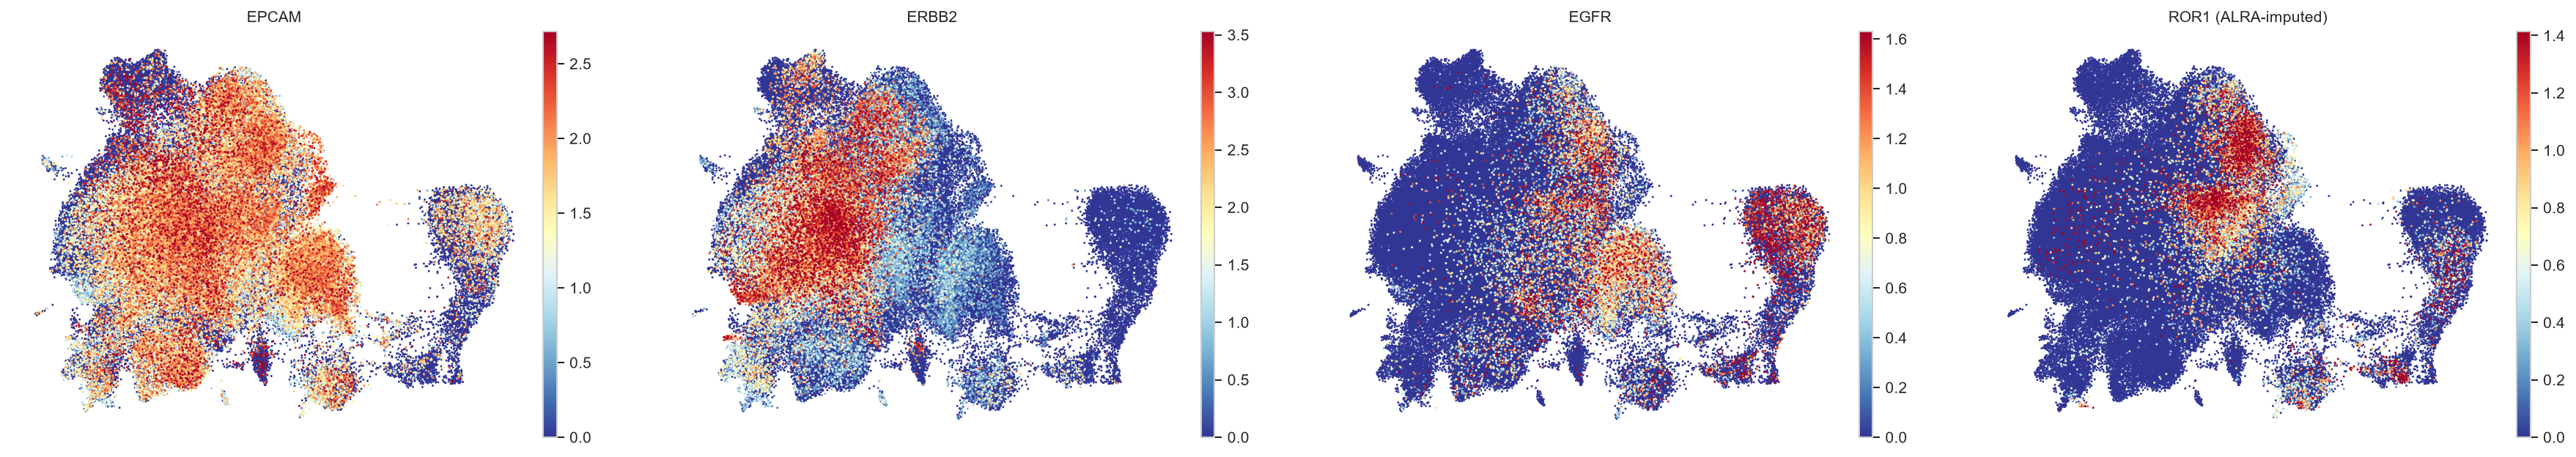

In [102]:
sc.pl.umap(
    epi,
    layer="lognorm",
    use_raw=False,
    color=["EPCAM", "ERBB2", "EGFR", "ROR1_alra"],
    title=["EPCAM", "ERBB2", "EGFR", "ROR1 (ALRA-imputed)"],
    ncols=4,
    cmap="RdYlBu_r",
    vmax="p99",
    size=8,
    frameon=False,
    show=False,
)
save_umap_figure(plt.gcf(), fig_dir / "antigen_expression_umap", close=False, overwrite=False)
plt.show()


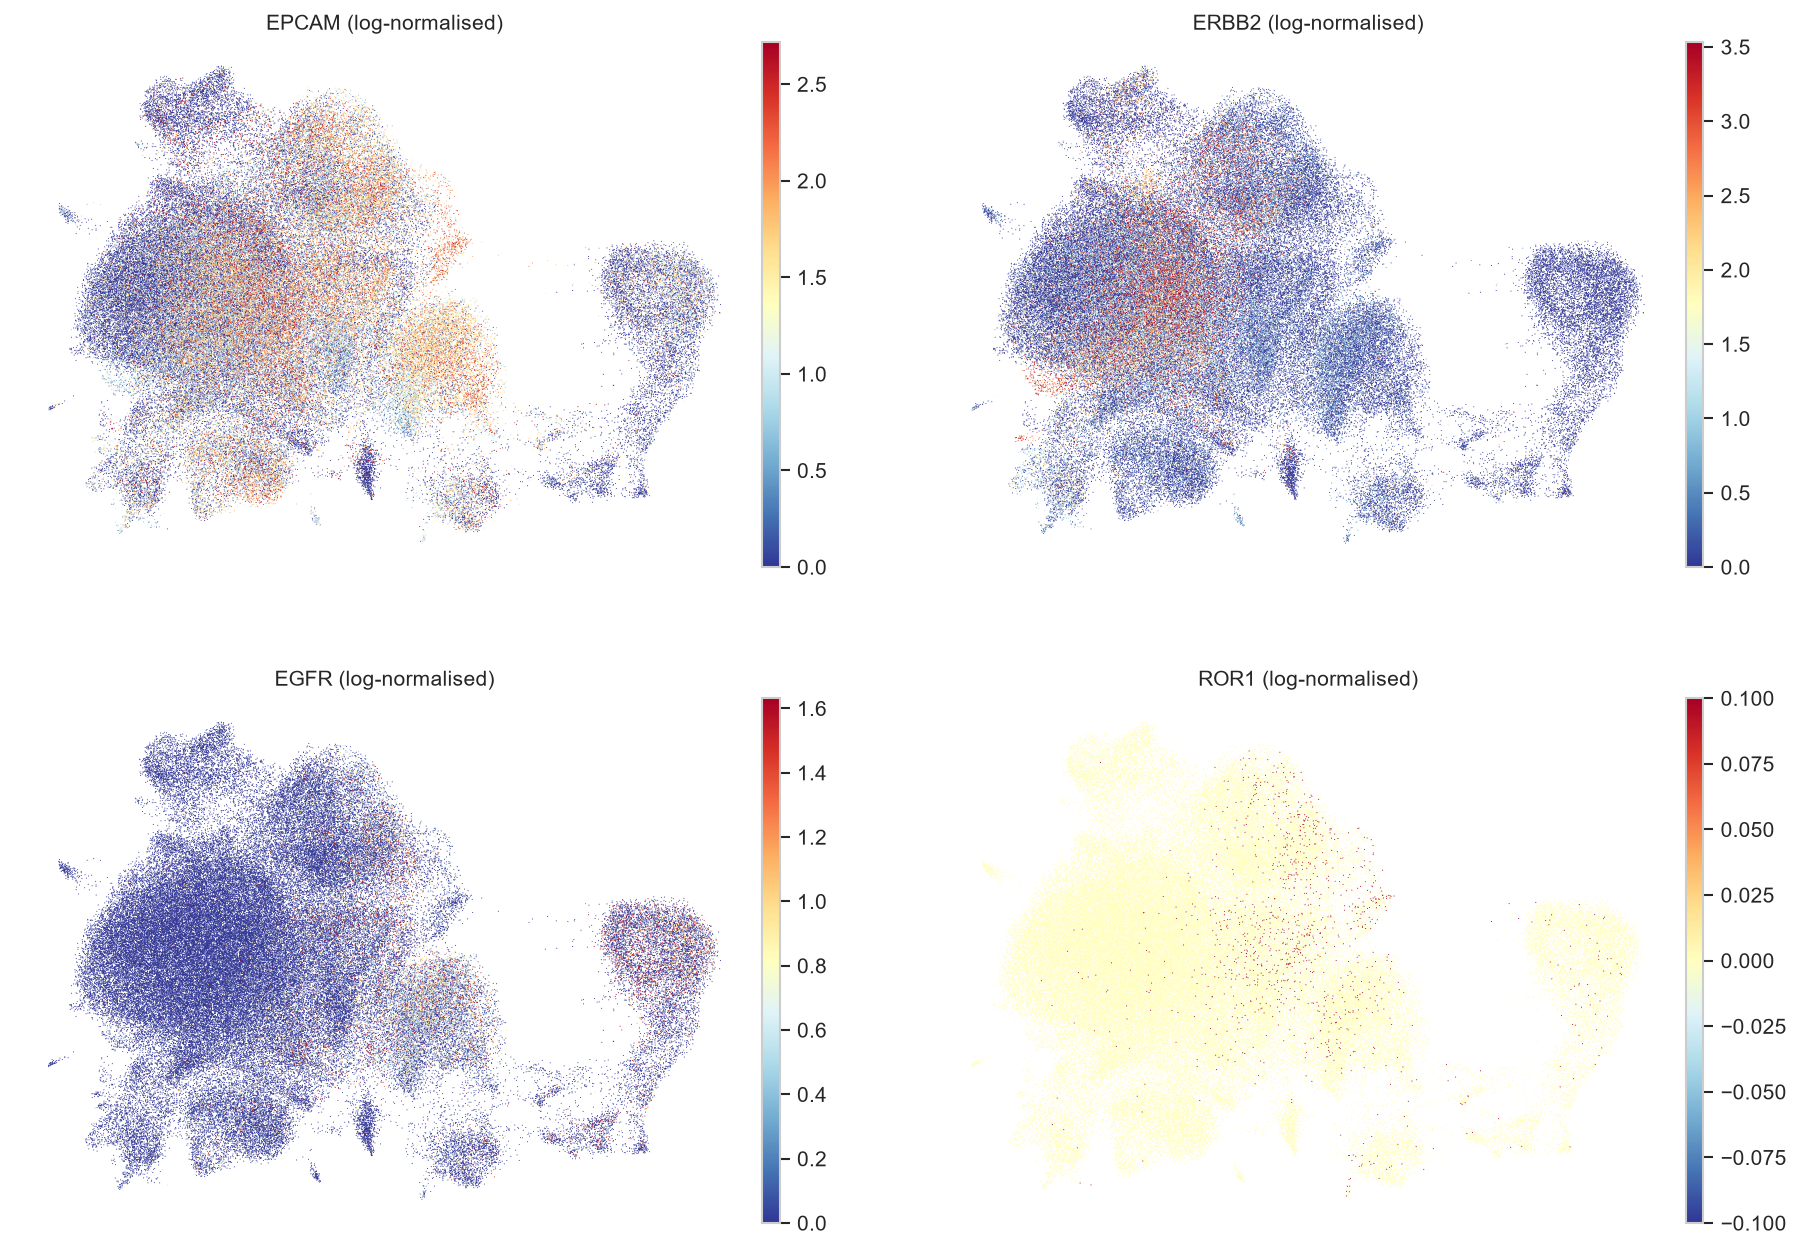

In [103]:
sc.pl.umap(
    epi,
    layer="lognorm",
    use_raw=False,
    color=["EPCAM", "ERBB2", "EGFR", "ROR1"],
    title=[f"{g} (log-normalised)" for g in ["EPCAM", "ERBB2", "EGFR", "ROR1"]],
    ncols=2,
    cmap="RdYlBu_r",
    vmax="p99",
    frameon=False,
    show=False,
)
save_umap_figure(plt.gcf(), fig_dir / "antigen_expression_umap_raw", close=False, overwrite=False)
plt.show()


## Transcript detection and reconstruction

Raw UMI categories and ALRA reconstruction diagnostics are calculated from the current epithelial object. ALRA values are computed in the preceding section and do not define transcript positivity.

In [104]:
def _digest(values):
    values = np.ascontiguousarray(values)
    return hashlib.sha256(values.tobytes()).hexdigest()


In [105]:
diagnostic_prefix = "ror1_transcript_diagnostics"


In [106]:
def _stack(ax, matrix, colours, *, percentages=False, totals=None):
    """Plot saved summaries without altering the source data."""
    x = np.arange(len(matrix))
    bottom = np.zeros(len(matrix))
    for column, colour in zip(matrix.columns, colours):
        values = matrix[column].to_numpy(float)
        ax.bar(
            x,
            values,
            bottom=bottom,
            width=0.64,
            color=colour,
            edgecolor="white",
            linewidth=0.65,
            label=column,
            zorder=3,
        )
        bottom += values
    ax.set_xticks(x, matrix.index.astype(str))
    peak = max(float(bottom.max()), 1.0)
    for position, value in enumerate(bottom):
        label = f"{value:.2f}%" if percentages else f"{int(value):,}"
        if totals is not None:
            label += (
                f"\n{100 * value / totals[position]:.2f}%" if totals[position] else ""
            )
        ax.text(
            position, value + peak * 0.025, label, ha="center", va="bottom", fontsize=9
        )
    ax.set_ylim(0, peak * (1.28 if totals is not None else 1.2))


In [107]:
alra_categories = ("0.1 < value ≤ 1", "1 < value ≤ 2", "2 < value ≤ 3", "value > 3")


In [108]:
alra_colors = ("#DDD5EA", "#AC96C8", "#7C5A9E", "#4A2D6B")


In [109]:
diagnostic_conditions = ("N", "ER+", "HER2+", "TN")


In [110]:
diagnostic_genes = ("ROR1", "EPCAM", "EGFR", "ERBB2")


In [111]:
diagnostic_palette = {
    "N": "#031A6B",
    "ER+": "#F46036",
    "HER2+": "#2CA02C",
    "TN": "#976391",
}


In [112]:
raw_umi_categories = ("1 UMI", "2 UMIs", "≥3 UMIs")


In [113]:
raw_umi_colors = ("#BED5E7", "#5899C2", "#174F78")


In [114]:
def plot_transcript_diagnostics(tables):
    """Six complementary diagnostics; no significance or reliability labels."""
    with plt.rc_context(
        {
            "font.size": 10,
            "axes.labelsize": 11,
            "axes.titlesize": 12,
            "xtick.labelsize": 10,
            "ytick.labelsize": 10,
        }
    ):
        fig, axes = plt.subplots(3, 2, figsize=(14.5, 12.5), layout="constrained")
        a, b, c, d, e, f = axes.flat
        matrix = (
            tables["gene_umi_categories"]
            .pivot(index="gene", columns="category", values="pct_all_epithelial")
            .reindex(index=diagnostic_genes, columns=raw_umi_categories)
        )
        _stack(a, matrix, raw_umi_colors, percentages=True)
        a.set(
            ylabel="All epithelial cells (%)",
            title="a  Raw UMI detection of target genes",
        )
        a.legend(frameon=False, fontsize=9, loc="upper right")
        matrix = (
            tables["ror1_umi_by_condition"]
            .pivot(index="raw_umi_category", columns="condition", values="n_cells")
            .reindex(
                index=("1 UMI", "2 UMIs", "3 UMIs", "≥4 UMIs"),
                columns=diagnostic_conditions,
            )
        )
        _stack(b, matrix, [diagnostic_palette[x] for x in diagnostic_conditions])
        b.set(
            xlabel="Raw ROR1 count",
            ylabel="Cells",
            title="b  Raw ROR1 count distribution",
        )
        b.legend(frameon=False, fontsize=9, loc="upper right", ncol=2)
        data = tables["ror1_detection_by_condition"]
        matrix = data.pivot(
            index="condition", columns="category", values="n_cells"
        ).reindex(index=diagnostic_conditions, columns=raw_umi_categories)
        totals = (
            data.groupby("condition", observed=True)
            .denominator.first()
            .reindex(diagnostic_conditions)
            .to_numpy()
        )
        _stack(c, matrix, raw_umi_colors, totals=totals)
        c.set(
            ylabel="Cells with ≥1 raw ROR1 UMI",
            title="c  Raw ROR1 detection by condition",
        )
        c.legend(frameon=False, fontsize=9, loc="upper left")
        matrix = (
            tables["alra_cumulative_thresholds"]
            .pivot(
                index="threshold_strictly_greater_than",
                columns="condition",
                values="n_cells",
            )
            .reindex(index=(0.1, 1.0, 2.0, 3.0), columns=diagnostic_conditions)
        )
        matrix.index = [">0.1", ">1", ">2", ">3"]
        _stack(d, matrix, [diagnostic_palette[x] for x in diagnostic_conditions])
        d.set(
            xlabel="ALRA-reconstructed ROR1 (cumulative cutoffs)",
            ylabel="Cells above cutoff",
            title="d  Saved ALRA values: diagnostic only",
        )
        d.legend(frameon=False, fontsize=9, loc="upper right", ncol=2)
        matrix = (
            tables["alra_exclusive_intervals"]
            .pivot(index="condition", columns="alra_interval", values="n_cells")
            .reindex(index=diagnostic_conditions, columns=alra_categories)
        )
        _stack(e, matrix, alra_colors)
        e.set(
            ylabel="Cells with ALRA ROR1 >0.1",
            title="e  ALRA intervals by condition: diagnostic only",
        )
        e.legend(frameon=False, fontsize=8.5, loc="upper left")
        cells = tables["ror1_cell_values"]
        finite = np.isfinite(cells.ROR1_alra.to_numpy())
        zero = cells.ROR1_raw_umi.eq(0).to_numpy() & finite
        f.scatter(
            cells.loc[zero, "ROR1_lognorm"],
            cells.loc[zero, "ROR1_alra"],
            s=4,
            color="#A9AFB5",
            alpha=0.3,
            linewidths=0,
            rasterized=True,
        )
        handles = [
            Line2D(
                [],
                [],
                marker="o",
                linestyle="none",
                color="#A9AFB5",
                label="Raw ROR1 = 0",
            )
        ]
        for condition in diagnostic_conditions:
            mask = (
                cells.condition.astype(str).eq(condition).to_numpy()
                & cells.ROR1_raw_umi.gt(0).to_numpy()
                & finite
            )
            f.scatter(
                cells.loc[mask, "ROR1_lognorm"],
                cells.loc[mask, "ROR1_alra"],
                s=4,
                color=diagnostic_palette[condition],
                alpha=0.65,
                linewidths=0,
                rasterized=True,
            )
            handles.append(
                Line2D(
                    [],
                    [],
                    marker="o",
                    linestyle="none",
                    color=diagnostic_palette[condition],
                    label=f"{condition}: raw ROR1 ≥1",
                )
            )
        f.set(
            xlabel="Log-normalised ROR1",
            ylabel="ALRA-reconstructed ROR1",
            title="f  Observed versus reconstructed ROR1",
        )
        f.legend(handles=handles, frameon=False, fontsize=8.5, loc="upper right")
        for axis in axes.flat:
            axis.spines[["top", "right"]].set_visible(False)
            axis.grid(False, axis="x")
            axis.grid(True, axis="y", color="#E3E6E8", linewidth=0.6)
            axis.set_axisbelow(True)
            axis.tick_params(length=0)
    return fig


In [115]:
def _column(adata, gene, layer):
    """Extract one feature without changing the source object or its layers."""
    matrix = adata[:, [gene]].layers[layer]
    return np.asarray(matrix.toarray() if sparse.issparse(matrix) else matrix).ravel()


In [116]:
transcript_figure_dir = fig_dir


In [117]:
detection_required = {"condition", "patient", "sample", "ROR1_alra"}


In [118]:
if not detection_required.issubset(epi.obs):
    raise ValueError(
        f"Missing metadata: {sorted(detection_required.difference(epi.obs))}"
    )


In [119]:
if epi.n_obs == 0:
    raise ValueError("The epithelial population is empty")


In [120]:
if not set(diagnostic_genes).issubset(epi.var_names) or not {
    "counts",
    "lognorm",
}.issubset(epi.layers):
    raise ValueError(
        "Four target genes plus saved counts and lognorm layers are required"
    )


In [121]:
detection_conditions = epi.obs["condition"].astype(str).to_numpy()


In [122]:
if not set(detection_conditions).issubset(diagnostic_conditions):
    raise ValueError("Unexpected condition labels in the epithelial population")


In [123]:
detection_raw = {
    detection_gene: _column(epi, detection_gene, "counts")
    for detection_gene in diagnostic_genes
}


In [124]:
for detection_gene, detection_values in detection_raw.items():
    if not (
        np.isfinite(detection_values).all()
        and (detection_values >= 0).all()
        and np.equal(detection_values, np.floor(detection_values)).all()
    ):
        raise ValueError(
            f"{detection_gene}: counts must be finite, non-negative raw integers"
        )


In [125]:
detection_observed = _column(epi, "ROR1", "lognorm")


In [126]:
detection_imputed = epi.obs["ROR1_alra"].to_numpy(dtype=float, copy=True)


In [127]:
if not np.isfinite(detection_observed).all() or (detection_observed < 0).any():
    raise ValueError("Saved log-normalised ROR1 must be finite and non-negative")


In [128]:
if (
    np.isinf(detection_imputed).any()
    or (detection_imputed[np.isfinite(detection_imputed)] < 0).any()
):
    raise ValueError(
        "ALRA values must be non-negative; missing reconstructions may be NaN"
    )


In [129]:
detection_gene_rows = []


In [130]:
for detection_gene, detection_values in detection_raw.items():
    detection_bins = (
        detection_values == 1,
        detection_values == 2,
        detection_values >= 3,
    )
    assert sum((int(detection_mask.sum()) for detection_mask in detection_bins)) == int(
        (detection_values > 0).sum()
    )
    for detection_category, detection_mask in zip(raw_umi_categories, detection_bins):
        detection_gene_rows.append(
            {
                "gene": detection_gene,
                "category": detection_category,
                "n_cells": int(detection_mask.sum()),
                "denominator": epi.n_obs,
                "pct_all_epithelial": 100 * detection_mask.mean(),
            }
        )


In [131]:
(
    detection_umi_rows,
    detection_condition_rows,
    detection_threshold_rows,
    detection_interval_rows,
) = ([], [], [], [])


In [132]:
detection_detail_bins = (
    detection_raw["ROR1"] == 1,
    detection_raw["ROR1"] == 2,
    detection_raw["ROR1"] == 3,
    detection_raw["ROR1"] >= 4,
)


In [133]:
for detection_condition in diagnostic_conditions:
    detection_mask = detection_conditions == detection_condition
    detection_size = int(detection_mask.sum())
    for detection_category, detection_raw_mask in zip(
        ("1 UMI", "2 UMIs", "3 UMIs", "≥4 UMIs"), detection_detail_bins
    ):
        detection_umi_rows.append(
            {
                "condition": detection_condition,
                "raw_umi_category": detection_category,
                "n_cells": int((detection_mask & detection_raw_mask).sum()),
                "denominator": detection_size,
            }
        )
    for detection_category, detection_raw_mask in zip(
        raw_umi_categories,
        (
            detection_raw["ROR1"] == 1,
            detection_raw["ROR1"] == 2,
            detection_raw["ROR1"] >= 3,
        ),
    ):
        detection_condition_rows.append(
            {
                "condition": detection_condition,
                "category": detection_category,
                "n_cells": int((detection_mask & detection_raw_mask).sum()),
                "denominator": detection_size,
            }
        )
    for detection_threshold in (0.1, 1.0, 2.0, 3.0):
        detection_threshold_rows.append(
            {
                "condition": detection_condition,
                "threshold_strictly_greater_than": detection_threshold,
                "n_cells": int(
                    (detection_mask & (detection_imputed > detection_threshold)).sum()
                ),
                "denominator": detection_size,
                "n_missing_alra": int(
                    (detection_mask & ~np.isfinite(detection_imputed)).sum()
                ),
            }
        )
    detection_intervals = (
        (detection_imputed > 0.1) & (detection_imputed <= 1),
        (detection_imputed > 1) & (detection_imputed <= 2),
        (detection_imputed > 2) & (detection_imputed <= 3),
        detection_imputed > 3,
    )
    assert sum(
        (
            int((detection_mask & detection_b).sum())
            for detection_b in detection_intervals
        )
    ) == int((detection_mask & (detection_imputed > 0.1)).sum())
    for detection_category, detection_interval in zip(
        alra_categories, detection_intervals
    ):
        detection_interval_rows.append(
            {
                "condition": detection_condition,
                "alra_interval": detection_category,
                "n_cells": int((detection_mask & detection_interval).sum()),
                "denominator": detection_size,
            }
        )


In [134]:
detection_cell_values = epi.obs[["sample", "patient", "condition"]].copy()


In [135]:
detection_cell_values["ROR1_raw_umi"] = detection_raw["ROR1"]


In [136]:
detection_cell_values["ROR1_lognorm"] = detection_observed


In [137]:
detection_cell_values["ROR1_alra"] = detection_imputed


In [138]:
detection_unit_values = (
    detection_cell_values.assign(
        raw_detected=detection_raw["ROR1"] > 0,
        raw_ge2=detection_raw["ROR1"] >= 2,
        alra_above_0_1=detection_imputed > 0.1,
    )
    .groupby(["patient", "condition"], observed=True)
    .agg(
        n_cells=("ROR1_raw_umi", "size"),
        n_raw_detected=("raw_detected", "sum"),
        n_raw_ge2=("raw_ge2", "sum"),
        n_alra_above_0_1=("alra_above_0_1", "sum"),
    )
    .reset_index()
)


In [139]:
detection_unit_values["raw_detection_pct"] = (
    100 * detection_unit_values.n_raw_detected / detection_unit_values.n_cells
)


In [140]:
transcript_tables = {
    "gene_umi_categories": pd.DataFrame(detection_gene_rows),
    "ror1_umi_by_condition": pd.DataFrame(detection_umi_rows),
    "ror1_detection_by_condition": pd.DataFrame(detection_condition_rows),
    "alra_cumulative_thresholds": pd.DataFrame(detection_threshold_rows),
    "alra_exclusive_intervals": pd.DataFrame(detection_interval_rows),
    "ror1_cell_values": detection_cell_values,
    "ror1_by_donor": detection_unit_values,
}


In [141]:
transcript_figure_dir = Path(transcript_figure_dir)


In [142]:
transcript_table_dir = (
    Path(df_dir) if df_dir is not None else transcript_figure_dir / "source_data"
)


In [143]:
transcript_figure_dir.mkdir(parents=True, exist_ok=True)


In [144]:
transcript_table_dir.mkdir(parents=True, exist_ok=True)


In [145]:
for transcript_name, transcript_frame in transcript_tables.items():
    if transcript_name == "ror1_cell_values":
        transcript_frame.to_csv(
            transcript_table_dir / f"{diagnostic_prefix}_{transcript_name}.csv.gz",
            index_label="cell_id",
            compression={"method": "gzip", "mtime": 0},
        )
    else:
        transcript_frame.to_csv(
            transcript_table_dir / f"{diagnostic_prefix}_{transcript_name}.csv",
            index=False,
        )


In [146]:
transcript_cells = transcript_tables["ror1_cell_values"]


In [147]:
transcript_manifest = {
    "population": "manually annotated epithelial cohort; all conditions and libraries",
    "n_cells": int(epi.n_obs),
    "n_libraries": int(transcript_cells["sample"].nunique()),
    "n_missing_alra": int(transcript_cells["ROR1_alra"].isna().sum()),
    "n_ror1_raw_detected": int(transcript_cells["ROR1_raw_umi"].gt(0).sum()),
    "n_ror1_alra_above_0_1": int(transcript_cells["ROR1_alra"].gt(0.1).sum()),
    "cell_order_sha256": hashlib.sha256(
        "\n".join(epi.obs_names.astype(str)).encode()
    ).hexdigest(),
    "raw_ror1_sha256": _digest(transcript_cells["ROR1_raw_umi"].to_numpy()),
    "lognorm_ror1_sha256": _digest(transcript_cells["ROR1_lognorm"].to_numpy()),
    "alra_ror1_sha256": _digest(transcript_cells["ROR1_alra"].to_numpy()),
    "annotation_method": epi.uns["annotation_mapping"]["method"],
    "source_data_sha256": {
        transcript_path.name: hashlib.sha256(transcript_path.read_bytes()).hexdigest()
        for transcript_path in sorted(
            transcript_table_dir.glob(f"{diagnostic_prefix}_*.csv*")
        )
    },
    "analysis": "descriptive, pooled cell summaries; no donor-level hypothesis test",
    "alra": "saved per-library reconstruction; display cutoffs do not define antigen positivity",
    "plot": "SVG/PDF: editable text, bars and individual scatter points; no rasterized point clouds",
}


In [148]:
(transcript_table_dir / f"{diagnostic_prefix}_manifest.json").write_text(
    json.dumps(transcript_manifest, indent=2) + "\n"
)


1829

In [149]:
transcript_caption = f"Raw transcript detection and ROR1 reconstruction diagnostics.\n\nAll panels use the same {epi.n_obs:,} manually annotated epithelial candidates from {transcript_manifest['n_libraries']} libraries, including normal-tissue and tumour-derived epithelium. These are pooled cell summaries, not independent donor tests. (a) Percentages of all epithelial cells with exactly one, exactly two or at least three raw UMIs for each gene. (b) ROR1 raw counts (1, 2, 3, ≥4), split by specimen condition. (c) ROR1-detecting cells by condition, split into mutually exclusive raw-count categories; labels show counts and percentages of all epithelial cells in that condition. (d) Cells above cumulative ALRA display cutoffs; a cell can contribute to several cutoffs. (e) The same saved ALRA values in mutually exclusive intervals above 0.1. (f) Saved log-normalised versus ALRA-reconstructed ROR1 for individual cells, with raw-zero cells grey and raw-detecting cells coloured by condition. The ALRA panels are exploratory diagnostics. ALRA values and their display thresholds do not define antigen positivity or validate recovered transcripts. Missing reconstructions, if any, are reported in the manifest and omitted from ALRA panels; raw-count panels retain their original denominators.\n"


In [151]:
(transcript_figure_dir / f"{diagnostic_prefix}_caption.md").write_text(
    transcript_caption,
    encoding="utf-8",
)

1231

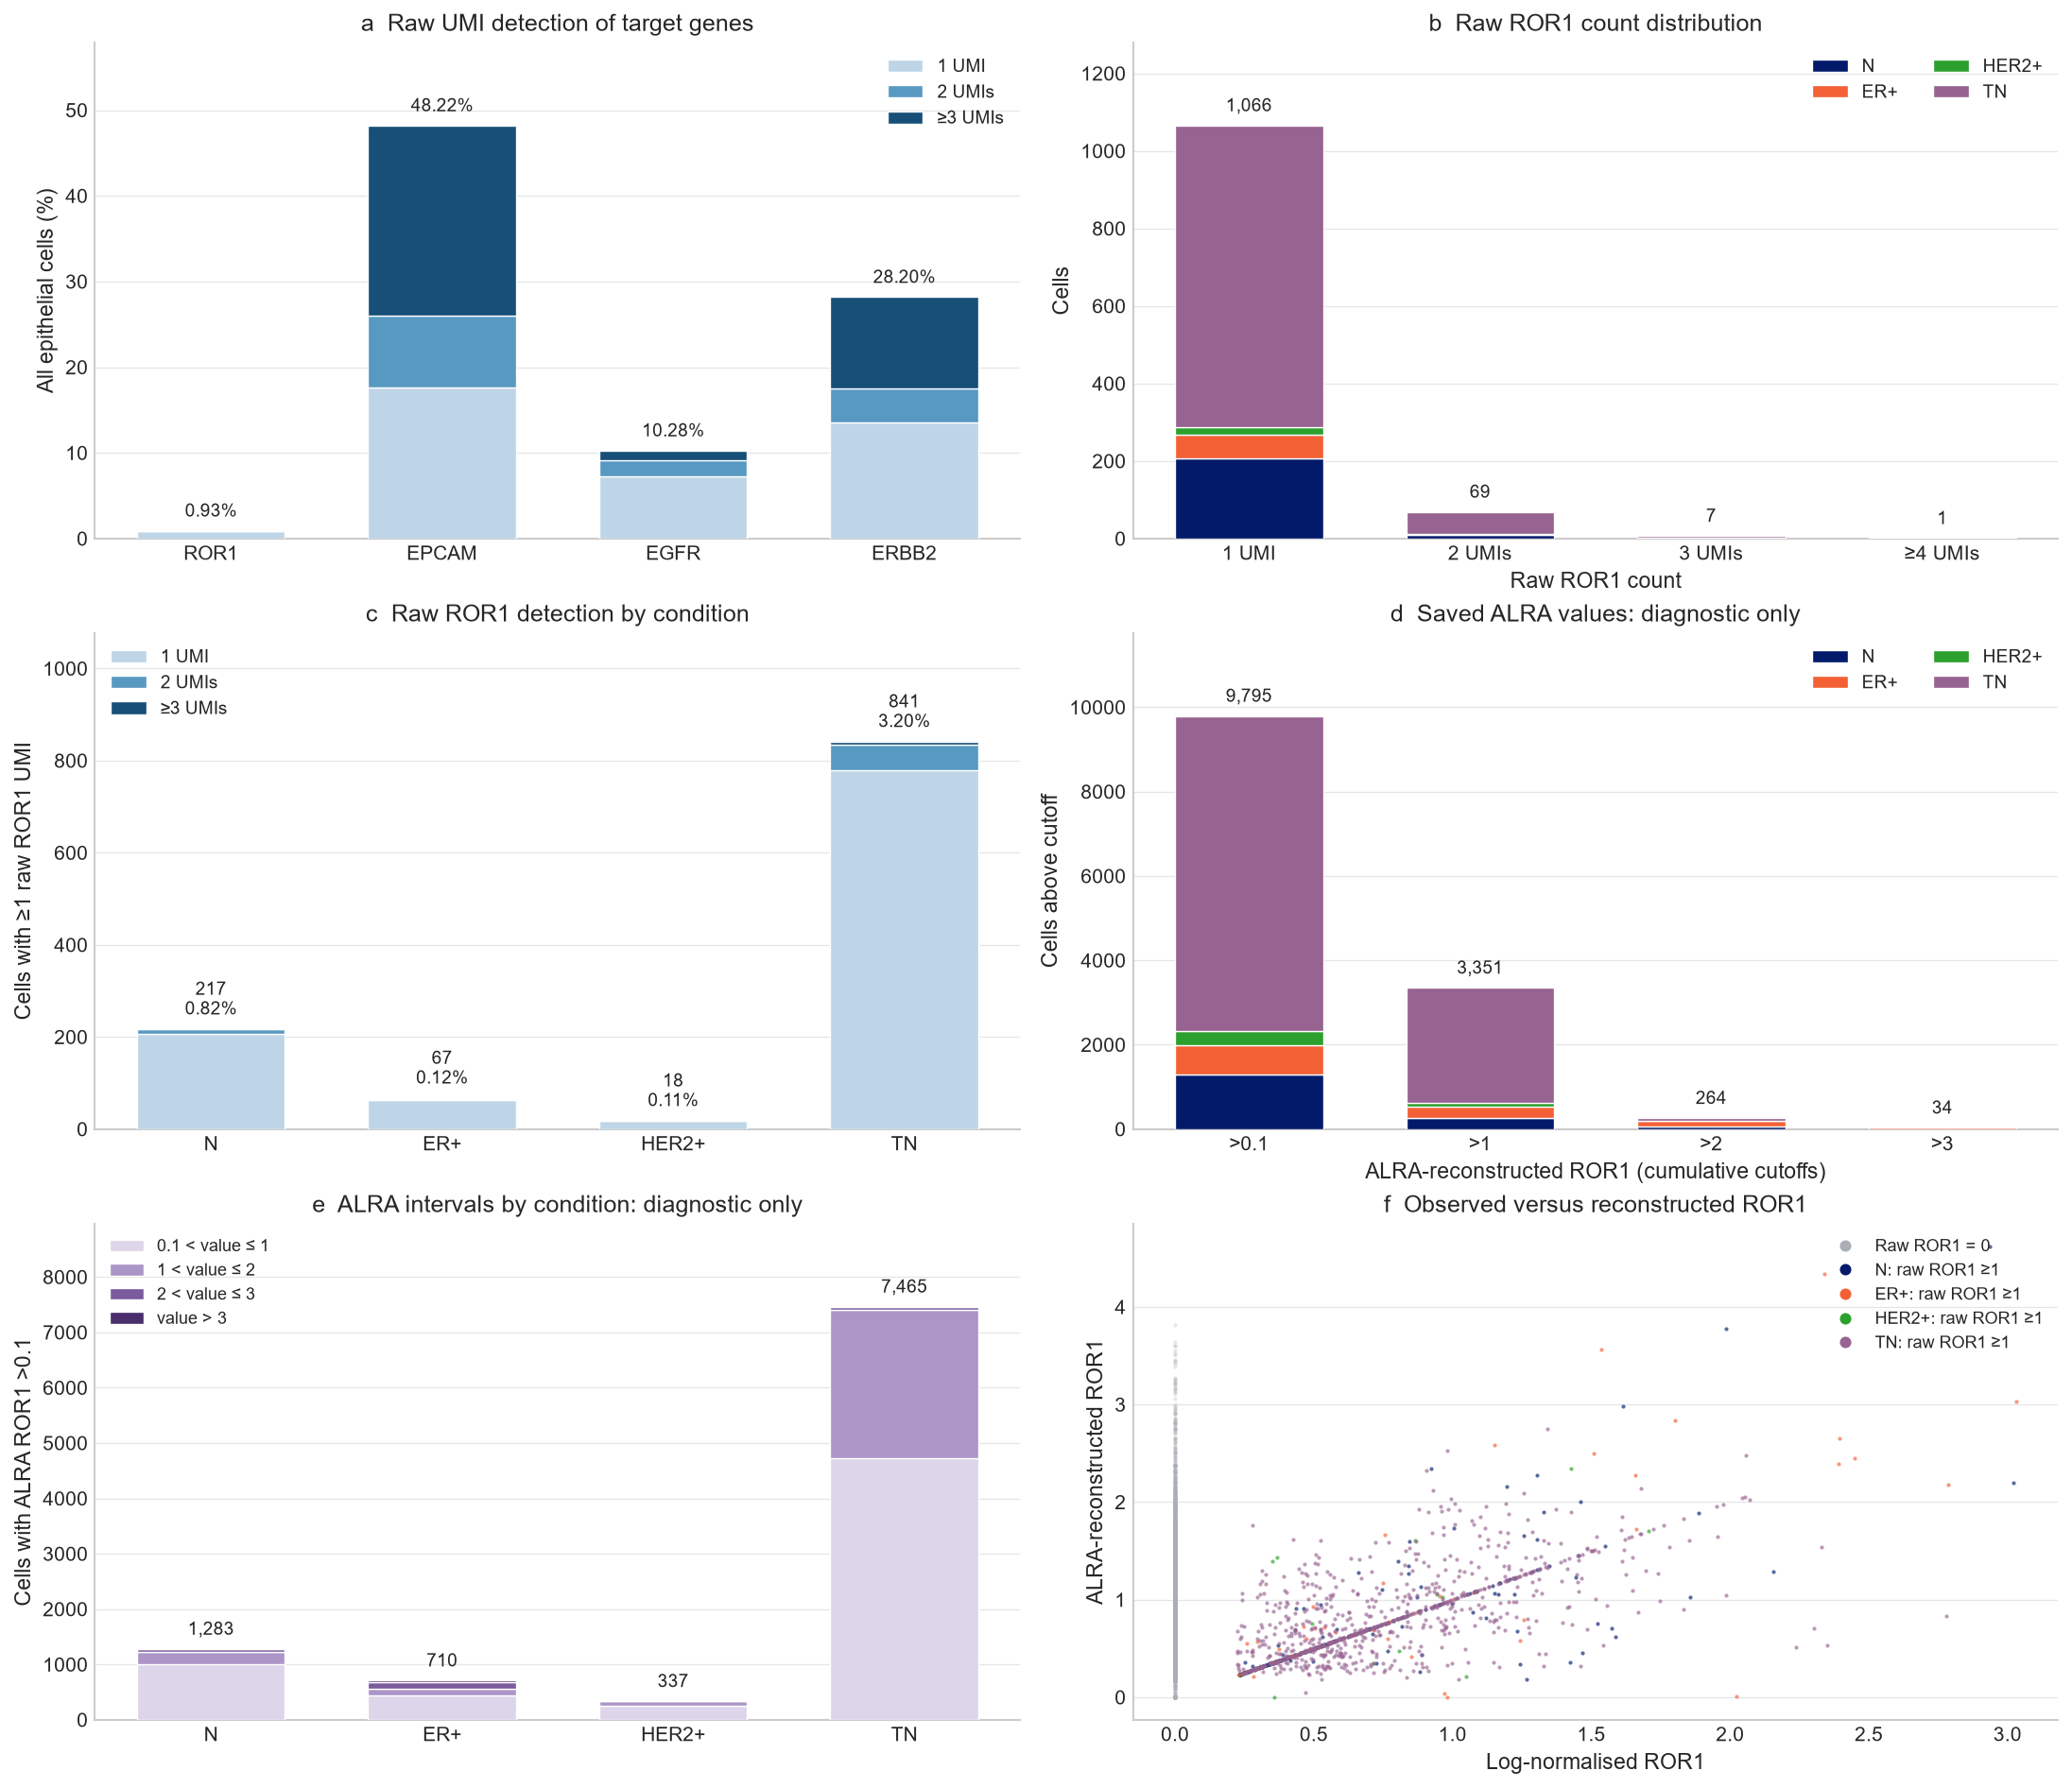

In [152]:
transcript_fig = plot_transcript_diagnostics(transcript_tables)
save_figure(transcript_fig, transcript_figure_dir / diagnostic_prefix, close=False, overwrite=False)
plt.show()


In [153]:
transcript_diagnostics = transcript_tables


## Antigen-pair co-expression

Positivity is called on raw counts, at one threshold shared by both pairs, so
that their prevalences are directly comparable.

In [154]:
def coexpression_group(adata, gene_a, gene_b, min_umi):
    a = raw_counts(adata, gene_a) >= min_umi
    b = raw_counts(adata, gene_b) >= min_umi
    labels = np.full(adata.n_obs, "Double negative", dtype=object)
    labels[a & ~b] = f"{gene_a} only"
    labels[~a & b] = f"{gene_b} only"
    labels[a & b] = "Double positive"
    return pd.Categorical(
        labels,
        categories=[
            "Double negative",
            f"{gene_a} only",
            f"{gene_b} only",
            "Double positive",
        ],
        ordered=True,
    )


In [155]:
for gene_a, gene_b in antigen_pairs:
    column = f"{gene_a}_{gene_b}_group"
    epi.obs[column] = coexpression_group(epi, gene_a, gene_b, primary_min_umi)
    n = int((epi.obs[column] == "Double positive").sum())
    print(f"{column}: {n:,} double positive ({100 * n / epi.n_obs:.3f}%)")


ROR1_EGFR_group: 349 double positive (0.283%)
EPCAM_ERBB2_group: 23,355 double positive (18.929%)


In [156]:
epi.uns["coexpression"] = {
    "expression": "raw UMI counts",
    "min_umi": primary_min_umi,
    "pairs": ["-".join(pair) for pair in antigen_pairs],
    "note": "ALRA values are not used for thresholding",
}


In [157]:
rows = []


In [158]:
for threshold_umi in min_umi_sweep:
    for gene_a, gene_b in antigen_pairs:
        groups = coexpression_group(epi, gene_a, gene_b, threshold_umi)
        double_positive = np.asarray(groups == "Double positive")
        rows.append(
            {
                "pair": f"{gene_a}-{gene_b}",
                "min_umi": threshold_umi,
                "condition": "all",
                "n_cells": epi.n_obs,
                "n_double_positive": int(double_positive.sum()),
                "pct_double_positive": 100 * double_positive.mean(),
            }
        )
        for condition in conditions:
            mask = (epi.obs["condition"].astype(str) == condition).to_numpy()
            rows.append(
                {
                    "pair": f"{gene_a}-{gene_b}",
                    "min_umi": threshold_umi,
                    "condition": condition,
                    "n_cells": int(mask.sum()),
                    "n_double_positive": int(double_positive[mask].sum()),
                    "pct_double_positive": 100 * double_positive[mask].mean(),
                }
            )


In [159]:
threshold_sweep = pd.DataFrame(rows)


In [160]:
display(
    threshold_sweep.pivot_table(
        index=["pair", "condition"], columns="min_umi", values="pct_double_positive"
    ).round(3)
)


min_umi                     1       2       3
pair        condition                        
EPCAM-ERBB2 ER+        11.403   3.399   1.286
            HER2+      59.128  42.035  31.880
            N          14.338   3.736   1.055
            TN         13.803   2.492   0.511
            all        18.929   8.449   5.167
ROR1-EGFR   ER+         0.024   0.000   0.000
            HER2+       0.012   0.000   0.000
            N           0.436   0.015   0.004
            TN          0.834   0.015   0.000
            all         0.283   0.006   0.001

In [161]:
threshold_sweep.to_csv(df_dir / "coexpression_threshold_sweep.csv", index=False)


In [162]:
condition_values = epi.obs["condition"].astype(str).to_numpy()


In [163]:
tumour_derived_only = epi.obs["tumour_derived"].astype(bool).to_numpy()


In [164]:
normal_tissue_only = ~tumour_derived_only


In [165]:
tumour_derived_cnv_high_only = (
    epi.obs["tumour_derived_cnv_high"].astype(bool).to_numpy()
)


In [166]:
g1_only = epi.obs["g1_cell"].astype(bool).to_numpy()


In [167]:
tumour_derived_cnv_high_g1_only = tumour_derived_cnv_high_only & g1_only


In [168]:
rows = []


In [169]:
for gene_a, gene_b in antigen_pairs:
    double_positive = np.asarray(
        coexpression_group(epi, gene_a, gene_b, primary_min_umi) == "Double positive"
    )
    scopes = [
        ("all_epithelial", np.ones(epi.n_obs, bool)),
        ("tumour_derived", tumour_derived_only),
        ("tumour_derived_cnv_high", tumour_derived_cnv_high_only),
        ("tumour_derived_cnv_high_g1", tumour_derived_cnv_high_g1_only),
    ]
    for scope, scope_mask in scopes:
        for condition in conditions:
            mask = scope_mask & (condition_values == condition)
            if mask.sum() == 0:
                continue
            rows.append(
                {
                    "pair": f"{gene_a}-{gene_b}",
                    "scope": scope,
                    "condition": condition,
                    "n_cells": int(mask.sum()),
                    "n_double_positive": int(double_positive[mask].sum()),
                    "pct_double_positive": 100 * double_positive[mask].mean(),
                }
            )


In [170]:
coexpression_by_scope = pd.DataFrame(rows)


In [171]:
display(
    coexpression_by_scope.pivot_table(
        index=["pair", "condition"], columns="scope", values="pct_double_positive"
    ).round(3)
)


scope                  all_epithelial  tumour_derived  \
pair        condition                                   
EPCAM-ERBB2 ER+                11.403          11.403   
            HER2+              59.128          59.128   
            N                  14.338             NaN   
            TN                 13.803          13.803   
ROR1-EGFR   ER+                 0.024           0.024   
            HER2+               0.012           0.012   
            N                   0.436             NaN   
            TN                  0.834           0.834   

scope                  tumour_derived_cnv_high  tumour_derived_cnv_high_g1  
pair        condition                                                       
EPCAM-ERBB2 ER+                         21.200                      22.608  
            HER2+                       57.960                      58.217  
            N                              NaN                         NaN  
            TN                          12.847                      14.073  
ROR1-EGFR   ER+                          0.034                       0.056  
            HER2+                        0.000                       0.000  
            N                              NaN                         NaN  
            TN                           1.100                       0.634

In [172]:
coexpression_by_scope.to_csv(
    df_dir / "coexpression_population_sensitivity.csv", index=False
)


In [173]:
cycle_scope_summary = coexpression_by_scope[
    coexpression_by_scope["scope"].isin(
        ["tumour_derived_cnv_high", "tumour_derived_cnv_high_g1"]
    )
].copy()


In [174]:
cycle_scope_summary.to_csv(
    df_dir / "coexpression_cnv_high_g1_sensitivity.csv", index=False
)


In [175]:
display(cycle_scope_summary.round(4))


,pair,scope,condition,n_cells,n_double_positive,pct_double_positive
7,ROR1-EGFR,tumour_derived_cnv_high,ER+,11816,4,0.0339
8,ROR1-EGFR,tumour_derived_cnv_high,HER2+,4491,0,0.0000
9,ROR1-EGFR,tumour_derived_cnv_high,TN,10002,110,1.0998
10,ROR1-EGFR,tumour_derived_cnv_high_g1,ER+,7117,4,0.0562
11,ROR1-EGFR,tumour_derived_cnv_high_g1,HER2+,3073,0,0.0000
12,ROR1-EGFR,tumour_derived_cnv_high_g1,TN,3155,20,0.6339
20,EPCAM-ERBB2,tumour_derived_cnv_high,ER+,11816,2505,21.2001
21,EPCAM-ERBB2,tumour_derived_cnv_high,HER2+,4491,2603,57.9604
22,EPCAM-ERBB2,tumour_derived_cnv_high,TN,10002,1285,12.8474
23,EPCAM-ERBB2,tumour_derived_cnv_high_g1,ER+,7117,1609,22.6078


In [176]:
rows = []


In [177]:
for gene_a, gene_b in antigen_pairs:
    a = raw_counts(epi, gene_a) >= primary_min_umi
    b = raw_counts(epi, gene_b) >= primary_min_umi
    for condition in conditions:
        mask = (epi.obs["condition"].astype(str) == condition).to_numpy()
        p_a = a[mask].mean()
        p_b = b[mask].mean()
        observed = (a & b)[mask].mean()
        expected = p_a * p_b
        rows.append(
            {
                "pair": f"{gene_a}-{gene_b}",
                "condition": condition,
                "pct_a": 100 * p_a,
                "pct_b": 100 * p_b,
                "pct_observed": 100 * observed,
                "pct_expected": 100 * expected,
                "observed_over_expected": (
                    observed / expected if expected > 0 else np.nan
                ),
            }
        )


In [178]:
independence = pd.DataFrame(rows)


In [179]:
display(independence.round(3))


,pair,condition,pct_a,pct_b,pct_observed,pct_expected,observed_over_expected
0,ROR1-EGFR,N,0.823,26.025,0.436,0.214,2.036
1,ROR1-EGFR,ER+,0.123,2.105,0.024,0.003,9.218
2,ROR1-EGFR,HER2+,0.109,3.040,0.012,0.003,3.655
3,ROR1-EGFR,TN,3.204,15.936,0.834,0.511,1.634
4,EPCAM-ERBB2,N,59.561,16.402,14.338,9.769,1.468
5,EPCAM-ERBB2,ER+,31.508,22.103,11.403,6.964,1.637
6,EPCAM-ERBB2,HER2+,63.276,82.640,59.128,52.291,1.131
7,EPCAM-ERBB2,TN,61.921,18.405,13.803,11.397,1.211


In [180]:
independence.to_csv(df_dir / "coexpression_observed_over_expected.csv", index=False)


## Tumour-derived versus normal-tissue co-detection

Everything below uses raw UMI counts. ALRA is used for visualisation only.

The unit of replication is the donor, not the cell. Pooled prevalence and donor-level
prevalence are reported separately because they answer different questions and can
disagree when donors differ greatly in size.

In [181]:
min_donor_cells = 100


In [182]:
window_group = np.where(
    normal_tissue_only,
    "Normal-tissue epithelium",
    epi.obs["condition"].astype(str) + " tumour-derived epithelium",
)


In [183]:
ror1_positive = raw_counts(epi, "ROR1") >= primary_min_umi


In [184]:
egfr_positive = raw_counts(epi, "EGFR") >= primary_min_umi


In [185]:
assert (
    "patient" in epi.obs.columns
), "patient metadata is required for donor-level inference"


In [186]:
assert epi.obs["patient"].notna().all(), "patient metadata contains missing values"


In [187]:
window = pd.DataFrame(
    {
        "group": window_group,
        "patient": epi.obs["patient"].astype(str).to_numpy(),
        "sample": epi.obs["sample"].astype(str).to_numpy(),
        "ror1": ror1_positive,
        "egfr": egfr_positive,
        "double_positive": ror1_positive & egfr_positive,
    }
)


In [188]:
window = window[window["group"] != "excluded"]


In [189]:
by_donor = (
    window.groupby(["group", "patient"], observed=True)
    .agg(
        n_cells=("double_positive", "size"),
        n_ror1=("ror1", "sum"),
        n_egfr=("egfr", "sum"),
        n_double_positive=("double_positive", "sum"),
    )
    .reset_index()
)


In [190]:
by_donor["prevalence"] = by_donor["n_double_positive"] / by_donor["n_cells"] * 100


In [191]:
def summarise_window(frame):
    """pooled and donor-level statistics side by side, never merged into one column"""
    rows = []
    for group, g in frame.groupby("group", observed=True):
        rows.append(
            {
                "group": group,
                "donors": len(g),
                "total_cells": int(g["n_cells"].sum()),
                "total_double_positive": int(g["n_double_positive"].sum()),
                "pooled_pct": g["n_double_positive"].sum() / g["n_cells"].sum() * 100,
                "donor_mean_pct": g["prevalence"].mean(),
                "donor_median_pct": g["prevalence"].median(),
                "donor_q1_pct": g["prevalence"].quantile(0.25),
                "donor_q3_pct": g["prevalence"].quantile(0.75),
                "donors_with_signal": int((g["n_double_positive"] > 0).sum()),
            }
        )
    return pd.DataFrame(rows)


In [192]:
eligible_donors = by_donor[by_donor["n_cells"] >= min_donor_cells]


In [193]:
origin_comparison = summarise_window(eligible_donors)


In [194]:
origin_comparison.to_csv(
    df_dir / "coexpression_tumour_derived_vs_normal.csv", index=False
)


In [195]:
display(origin_comparison.round(4))


,group,donors,total_cells,total_double_positive,pooled_pct,donor_mean_pct,donor_median_pct,donor_q1_pct,donor_q3_pct,donors_with_signal
0,ER+ tumour-derived epithelium,16,54256,13,0.0240,0.0803,0.0000,0.0000,0.0391,6
1,HER2+ tumour-derived epithelium,6,16515,2,0.0121,0.0087,0.0000,0.0000,0.0000,1
2,Normal-tissue epithelium,13,26363,115,0.4362,0.4088,0.3161,0.1330,0.4892,11
3,TN tumour-derived epithelium,6,26194,218,0.8323,0.9301,0.6883,0.5958,1.4670,5


In [196]:
rows = []


In [197]:
for rule in [0, 50, 100]:
    summary = summarise_window(by_donor[by_donor["n_cells"] >= rule]).set_index("group")
    tn = summary.loc["TN tumour-derived epithelium"]
    normal = summary.loc["Normal-tissue epithelium"]
    rows.append(
        {
            "min_donor_cells": rule,
            "tn_donors": int(tn["donors"]),
            "tn_pooled_pct": tn["pooled_pct"],
            "tn_donor_mean_pct": tn["donor_mean_pct"],
            "normal_pooled_pct": normal["pooled_pct"],
            "pooled_ratio": tn["pooled_pct"] / normal["pooled_pct"],
        }
    )


In [198]:
eligibility_sensitivity = pd.DataFrame(rows)


In [199]:
eligibility_sensitivity.to_csv(
    df_dir / "coexpression_eligibility_sensitivity.csv", index=False
)


In [200]:
display(eligibility_sensitivity.round(4))


,min_donor_cells,tn_donors,tn_pooled_pct,tn_donor_mean_pct,normal_pooled_pct,pooled_ratio
0,0,7,0.8343,1.0618,0.4362,1.9127
1,50,7,0.8343,1.0618,0.4362,1.9127
2,100,6,0.8323,0.9301,0.4362,1.9079


### CNV-high and G1 sensitivity

The CNV-high analysis is repeated after restricting both tumour-derived and
normal reference cells to G1. This tests whether cycling transcription drives
the CNV-based enrichment without treating G1 as evidence against malignancy.

In [201]:
def scoped_donor_prevalence(scope, tumour_mask, normal_mask):
    included = tumour_mask | normal_mask
    frame = pd.DataFrame(
        {
            "scope": scope,
            "condition": np.where(normal_mask, "N", condition_values),
            "patient": epi.obs["patient"].astype(str).to_numpy(),
            "double_positive": ror1_positive & egfr_positive,
        }
    )
    frame = frame[included]
    donor = (
        frame.groupby(["scope", "condition", "patient"], observed=True)
        .agg(
            n_cells=("double_positive", "size"),
            n_double_positive=("double_positive", "sum"),
        )
        .reset_index()
    )
    donor["prevalence"] = 100 * donor["n_double_positive"] / donor["n_cells"]
    return donor


In [202]:
cycle_sensitivity_donors = pd.concat(
    [
        scoped_donor_prevalence(
            "tumour_derived", tumour_derived_only, normal_tissue_only
        ),
        scoped_donor_prevalence(
            "tumour_derived_cnv_high", tumour_derived_cnv_high_only, normal_tissue_only
        ),
        scoped_donor_prevalence(
            "tumour_derived_cnv_high_g1",
            tumour_derived_cnv_high_g1_only,
            normal_tissue_only & g1_only,
        ),
    ],
    ignore_index=True,
)


In [203]:
cycle_sensitivity_donors = cycle_sensitivity_donors[
    cycle_sensitivity_donors["n_cells"] >= min_donor_cells
].copy()


In [204]:
cycle_sensitivity_donors.to_csv(
    df_dir / "coexpression_cnv_high_g1_by_donor.csv", index=False
)


In [205]:
cycle_sensitivity_summary = (
    cycle_sensitivity_donors.groupby(["scope", "condition"], observed=True)
    .agg(
        donors=("patient", "nunique"),
        total_cells=("n_cells", "sum"),
        total_double_positive=("n_double_positive", "sum"),
        donor_mean_pct=("prevalence", "mean"),
        donor_median_pct=("prevalence", "median"),
    )
    .reset_index()
)


In [206]:
cycle_sensitivity_summary["pooled_pct"] = (
    100
    * cycle_sensitivity_summary["total_double_positive"]
    / cycle_sensitivity_summary["total_cells"]
)


In [207]:
cycle_sensitivity_summary.to_csv(
    df_dir / "coexpression_cnv_high_g1_summary.csv", index=False
)


In [208]:
display(cycle_sensitivity_summary.round(4))


,scope,condition,donors,total_cells,total_double_positive,donor_mean_pct,donor_median_pct,pooled_pct
0,tumour_derived,ER+,16,54256,13,0.0803,0.0000,0.0240
1,tumour_derived,HER2+,6,16515,2,0.0087,0.0000,0.0121
2,tumour_derived,N,13,26363,115,0.4088,0.3161,0.4362
3,tumour_derived,TN,6,26194,218,0.9301,0.6883,0.8323
4,tumour_derived_cnv_high,ER+,15,11741,4,0.0801,0.0000,0.0341
5,tumour_derived_cnv_high,HER2+,6,4491,0,0.0000,0.0000,0.0000
6,tumour_derived_cnv_high,N,13,26363,115,0.4088,0.3161,0.4362
7,tumour_derived_cnv_high,TN,6,9988,109,1.2185,0.9693,1.0913
8,tumour_derived_cnv_high_g1,ER+,15,7062,4,0.1246,0.0000,0.0566
9,tumour_derived_cnv_high_g1,HER2+,5,2974,0,0.0000,0.0000,0.0000


## Exact conditional ROR1–EGFR overlap

Observed double-positive prevalence does not establish that the two transcripts
co-occur more often than expected from their separate detection rates. This test
conditions on the observed ROR1-positive and EGFR-positive margins within each
patient, technical sample and library-depth bin. Under conditional independence,
the overlap in each stratum is hypergeometric. Convolving those stratum-specific
distributions gives an exact upper-tail probability without Monte-Carlo error.

The main analysis uses TN tumour-derived epithelium with at least one raw UMI per
gene with ten within-sample depth bins. Other tumour groups, normal epithelium,
the two-UMI threshold and alternative bin counts are sensitivity analyses with
Holm adjustment. The pooled conditional test is cell-level evidence within this
cohort; donor-level direction and an exact sign test are reported separately for
generalisation across patients.

In [209]:
overlap_depth_bins = [5, 10, 20]


In [210]:
overlap_primary_bins = 10


In [211]:
overlap_thresholds = [1, 2]


In [212]:
overlap_group_order = [
    "TN tumour-derived epithelium",
    "ER+ tumour-derived epithelium",
    "HER2+ tumour-derived epithelium",
    "Normal-tissue epithelium",
]


In [213]:
overlap_library_size = np.rint(epi.obs["total_counts"].to_numpy(float)).astype(np.int64)


In [214]:
overlap_base = pd.DataFrame(
    {
        "group": window_group,
        "patient": epi.obs["patient"].astype(str).to_numpy(),
        "sample": epi.obs["sample"].astype(str).to_numpy(),
        "total_counts": overlap_library_size,
        "ror1_count": raw_counts(epi, "ROR1").astype(np.int64),
        "egfr_count": raw_counts(epi, "EGFR").astype(np.int64),
    }
)


In [215]:
overlap_base = overlap_base[overlap_base["group"] != "excluded"].copy()


In [216]:
eligible_overlap_units = set(
    eligible_donors[["group", "patient"]].itertuples(index=False, name=None)
)


In [217]:
overlap_base = overlap_base[
    pd.MultiIndex.from_frame(overlap_base[["group", "patient"]]).isin(
        eligible_overlap_units
    )
].copy()


In [218]:
assert overlap_base["total_counts"].gt(0).all()


In [219]:
assert set(overlap_base["group"]).issubset(overlap_group_order)


In [220]:
def add_within_sample_depth_bins(frame, n_bins):
    """Assign deterministic quantile bins without mixing technical samples."""
    frame = frame.copy()

    def assign_bins(values):
        requested = min(n_bins, len(values))
        bins = pd.qcut(values, q=requested, labels=False, duplicates="drop")
        if bins.isna().all():
            return pd.Series(0, index=values.index, dtype=int)
        return bins.fillna(0).astype(int)

    frame["depth_bin"] = frame.groupby(["patient", "sample"], observed=True)[
        "total_counts"
    ].transform(assign_bins)
    return frame


In [221]:
def stratum_overlap_distribution(n_cells, n_ror1, n_egfr):
    lower = max(0, n_ror1 + n_egfr - n_cells)
    upper = min(n_ror1, n_egfr)
    support = np.arange(lower, upper + 1)
    distribution = np.zeros(upper + 1, dtype=float)
    distribution[lower : upper + 1] = hypergeom.pmf(support, n_cells, n_ror1, n_egfr)
    return distribution


In [222]:
def exact_stratified_overlap(frame):
    """Exact overlap test across patient, sample and depth strata."""
    distribution = np.array([1.0])
    observed = 0
    expected = 0.0
    variance = 0.0
    n_strata = 0
    groups = frame.groupby(
        ["patient", "sample", "depth_bin"], observed=True, sort=False
    )
    for _, stratum in groups:
        n_cells = len(stratum)
        n_ror1 = int(stratum["ror1_positive"].sum())
        n_egfr = int(stratum["egfr_positive"].sum())
        observed += int(stratum["double_positive"].sum())
        expected += n_ror1 * n_egfr / n_cells
        if n_cells > 1:
            variance += (
                n_egfr
                * (n_ror1 / n_cells)
                * (1 - n_ror1 / n_cells)
                * ((n_cells - n_egfr) / (n_cells - 1))
            )
        distribution = np.convolve(
            distribution, stratum_overlap_distribution(n_cells, n_ror1, n_egfr)
        )
        distribution /= distribution.sum()
        n_strata += 1
    p_upper = (
        float(distribution[observed:].sum()) if observed < len(distribution) else 0.0
    )
    return {
        "n_cells": int(len(frame)),
        "n_strata": n_strata,
        "n_ror1": int(frame["ror1_positive"].sum()),
        "n_egfr": int(frame["egfr_positive"].sum()),
        "observed_double_positive": observed,
        "expected_double_positive": expected,
        "variance_under_independence": variance,
        "observed_over_expected": observed / expected if expected > 0 else np.nan,
        "p_upper_exact": p_upper,
        "p_underflow": p_upper == 0.0,
    }


In [223]:
cohort_rows = []


In [224]:
donor_rows = []


In [225]:
for threshold_umi in overlap_thresholds:
    for n_bins in overlap_depth_bins:
        analysed = overlap_base.copy()
        analysed["ror1_positive"] = analysed["ror1_count"] >= threshold_umi
        analysed["egfr_positive"] = analysed["egfr_count"] >= threshold_umi
        analysed["double_positive"] = (
            analysed["ror1_positive"] & analysed["egfr_positive"]
        )
        analysed = add_within_sample_depth_bins(analysed, n_bins)
        for group in overlap_group_order:
            group_frame = analysed[analysed["group"] == group]
            if group_frame.empty:
                continue
            cohort_result = exact_stratified_overlap(group_frame)
            cohort_result.update(
                {
                    "group": group,
                    "min_umi": threshold_umi,
                    "depth_bins_requested": n_bins,
                    "n_donors": int(group_frame["patient"].nunique()),
                    "primary_test": bool(
                        group == "TN tumour-derived epithelium"
                        and threshold_umi == primary_min_umi
                        and (n_bins == overlap_primary_bins)
                    ),
                }
            )
            cohort_rows.append(cohort_result)
            for patient, donor_frame in group_frame.groupby("patient", observed=True):
                donor_result = exact_stratified_overlap(donor_frame)
                donor_result.update(
                    {
                        "group": group,
                        "patient": str(patient),
                        "min_umi": threshold_umi,
                        "depth_bins_requested": n_bins,
                    }
                )
                donor_rows.append(donor_result)


In [226]:
overlap_cohort = pd.DataFrame(cohort_rows)


In [227]:
overlap_by_donor = pd.DataFrame(donor_rows)


In [228]:
overlap_cohort["p_holm_all_tests"] = multipletests(
    overlap_cohort["p_upper_exact"], method="holm"
)[1]


In [229]:
overlap_cohort.to_csv(
    df_dir / "ror1_egfr_exact_conditional_overlap_cohort.csv", index=False
)


In [230]:
overlap_by_donor.to_csv(
    df_dir / "ror1_egfr_exact_conditional_overlap_by_donor.csv", index=False
)


In [231]:
direction_rows = []


In [232]:
for keys, donors in overlap_by_donor.groupby(
    ["group", "min_umi", "depth_bins_requested"], observed=True
):
    group, threshold_umi, n_bins = keys
    informative = donors[donors["expected_double_positive"] > 0].copy()
    delta = (
        informative["observed_double_positive"]
        - informative["expected_double_positive"]
    )
    ties = np.isclose(delta, 0.0, atol=1e-12)
    positive = int((delta[~ties] > 0).sum())
    negative = int((delta[~ties] < 0).sum())
    denominator = positive + negative
    sign_p = (
        binomtest(positive, denominator, p=0.5, alternative="greater").pvalue
        if denominator > 0
        else np.nan
    )
    direction_rows.append(
        {
            "group": group,
            "min_umi": int(threshold_umi),
            "depth_bins_requested": int(n_bins),
            "informative_donors": int(len(informative)),
            "positive_donors": positive,
            "negative_donors": negative,
            "ties_removed": int(ties.sum()),
            "sign_test_denominator": denominator,
            "sign_test_p_upper": sign_p,
        }
    )


In [233]:
overlap_direction = pd.DataFrame(direction_rows)


In [234]:
valid_sign = overlap_direction["sign_test_p_upper"].notna()


In [235]:
overlap_direction["sign_test_p_holm_all_tests"] = np.nan


In [236]:
overlap_direction.loc[valid_sign, "sign_test_p_holm_all_tests"] = multipletests(
    overlap_direction.loc[valid_sign, "sign_test_p_upper"], method="holm"
)[1]


In [237]:
overlap_direction.to_csv(
    df_dir / "ror1_egfr_exact_conditional_overlap_donor_direction.csv", index=False
)


In [238]:
display_columns = [
    "group",
    "n_donors",
    "n_cells",
    "observed_double_positive",
    "expected_double_positive",
    "observed_over_expected",
    "p_upper_exact",
]


In [239]:
display(
    overlap_cohort[
        (overlap_cohort["min_umi"] == primary_min_umi)
        & (overlap_cohort["depth_bins_requested"] == overlap_primary_bins)
    ][display_columns].round(4)
)


,group,n_donors,n_cells,observed_double_positive,expected_double_positive,observed_over_expected,p_upper_exact
4,TN tumour-derived epithelium,6,26194,218,201.5593,1.0816,0.0843
5,ER+ tumour-derived epithelium,16,54256,13,5.4496,2.3855,0.0013
6,HER2+ tumour-derived epithelium,6,16515,2,0.8458,2.3647,0.2049
7,Normal-tissue epithelium,13,26363,115,100.5360,1.1439,0.0155


In [240]:
primary_overlap_donors = overlap_by_donor[
    (overlap_by_donor["min_umi"] == primary_min_umi)
    & (overlap_by_donor["depth_bins_requested"] == overlap_primary_bins)
    & overlap_by_donor["group"].isin(
        ["TN tumour-derived epithelium", "Normal-tissue epithelium"]
    )
].copy()


In [241]:
epi.uns["ror1_egfr_exact_overlap"] = {
    "expression": "raw UMI counts",
    "primary_group": "TN tumour-derived epithelium",
    "population_definition": "tumour-specimen origin",
    "primary_min_umi": int(primary_min_umi),
    "primary_depth_bins": int(overlap_primary_bins),
    "strata": "patient, technical sample and within-sample library-depth bin",
    "null": "conditional independence with fixed gene-positive margins",
    "primary_p_upper_exact": float(
        overlap_cohort.loc[overlap_cohort["primary_test"], "p_upper_exact"].iloc[0]
    ),
}


In [242]:
tn_prevalence = eligible_donors.loc[
    eligible_donors["group"] == "TN tumour-derived epithelium", "prevalence"
].to_numpy()


In [243]:
normal_prevalence = eligible_donors.loc[
    eligible_donors["group"] == "Normal-tissue epithelium", "prevalence"
].to_numpy()


In [244]:
observed_difference = tn_prevalence.mean() - normal_prevalence.mean()


In [245]:
pooled = np.concatenate([tn_prevalence, normal_prevalence])


In [246]:
n_tn = len(tn_prevalence)


In [247]:
all_indices = np.arange(len(pooled))


In [248]:
permuted = np.array(
    [
        pooled[list(assignment)].mean()
        - pooled[np.setdiff1d(all_indices, assignment, assume_unique=True)].mean()
        for assignment in combinations(all_indices, n_tn)
    ]
)


In [249]:
assert len(permuted) == comb(len(pooled), n_tn)


In [250]:
rng = np.random.default_rng(0)


In [251]:
bootstrapped = np.array(
    [
        rng.choice(tn_prevalence, len(tn_prevalence)).mean()
        - rng.choice(normal_prevalence, len(normal_prevalence)).mean()
        for _ in range(10000)
    ]
)


In [252]:
donor_inference = {
    "tn_donor_prevalences": tn_prevalence.tolist(),
    "normal_donor_prevalences": normal_prevalence.tolist(),
    "difference_pp": float(observed_difference),
    "bootstrap_ci_pp": [
        float(np.percentile(bootstrapped, 2.5)),
        float(np.percentile(bootstrapped, 97.5)),
    ],
    "exact_permutation_p": float((np.abs(permuted) >= abs(observed_difference) - 1e-12).mean()),
    "n_permutations": int(len(permuted)),
    "mann_whitney_p": float(mannwhitneyu(tn_prevalence, normal_prevalence).pvalue),
    "primary_test": "exact permutation on the donor-level difference in mean prevalence; Mann-Whitney reported as sensitivity only",
}


In [253]:
epi.uns["coexpression_window"] = donor_inference


In [254]:
display(donor_inference)


{'tn_donor_prevalences': [0.6493506493506493,
  0.0,
  0.5778915215058202,
  0.7272727272727273,
  1.9124521886952826,
  1.7136329017517136],
 'normal_donor_prevalences': [0.0,
  0.19728729963008632,
  0.0,
  0.5578800557880056,
  0.24600246002460024,
  0.13297872340425532,
  0.36591740721380034,
  0.31605562579013907,
  1.3260173754000915,
  0.12315270935960591,
  0.4892367906066536,
  0.3664681630783326,
  1.1933174224343674],
 'difference_pp': 0.52130661096296,
 'bootstrap_ci_pp': [-0.04091625377319623, 1.1101373207677698],
 'exact_permutation_p': 0.05749668288367979,
 'n_permutations': 27132,
 'mann_whitney_p': 0.07168214070464479,
 'primary_test': 'exact permutation on the donor-level difference in mean prevalence; Mann-Whitney reported as sensitivity only'}

## Donor-level co-detection

One point is shown per donor so that a large tumour cannot dominate the
comparison. Tumour groups contain epithelial cells from tumour specimens;
the reference group contains epithelial cells from normal tissue. This is a
specimen-origin comparison and does not classify every tumour-derived cell as
malignant. Positivity is defined from raw counts.

In [255]:
patient_values = epi.obs["patient"].astype(str).to_numpy()


In [256]:
def donor_prevalence(gene_a, gene_b, min_umi):
    """one row per donor: eligible cells and the fraction positive for both genes"""
    positive = (raw_counts(epi, gene_a) >= min_umi) & (
        raw_counts(epi, gene_b) >= min_umi
    )
    frame = pd.DataFrame(
        {"group": window_group, "patient": patient_values, "double_positive": positive}
    )
    frame = frame[frame["group"] != "excluded"]
    donor = (
        frame.groupby(["group", "patient"], observed=True)
        .agg(
            n_cells=("double_positive", "size"),
            n_double_positive=("double_positive", "sum"),
        )
        .reset_index()
    )
    donor["prevalence"] = donor["n_double_positive"] / donor["n_cells"] * 100
    donor["pair"] = f"{gene_a}+{gene_b}"
    donor["min_umi"] = min_umi
    return donor[donor["n_cells"] >= min_donor_cells]


In [257]:
donor_levels = pd.concat(
    [
        donor_prevalence(a, b, threshold)
        for a, b in antigen_pairs
        for threshold in min_umi_sweep
    ],
    ignore_index=True,
)


In [258]:
donor_levels.to_csv(df_dir / "coexpression_donor_prevalence.csv", index=False)


In [259]:
display(
    donor_levels.groupby(["pair", "min_umi", "group"], observed=True)["prevalence"]
    .describe()
    .round(3)
)


count    mean     std  \
pair        min_umi group                                                    
EPCAM+ERBB2 1       ER+ tumour-derived epithelium     16.0  16.227  17.068   
                    HER2+ tumour-derived epithelium    6.0  53.844  19.525   
                    Normal-tissue epithelium          13.0  15.126   8.167   
                    TN tumour-derived epithelium       6.0  17.989  10.737   
            2       ER+ tumour-derived epithelium     16.0   6.073   9.008   
                    HER2+ tumour-derived epithelium    6.0  35.579  23.332   
                    Normal-tissue epithelium          13.0   3.906   3.252   
                    TN tumour-derived epithelium       6.0   4.133   3.711   
            3       ER+ tumour-derived epithelium     16.0   2.541   4.227   
                    HER2+ tumour-derived epithelium    6.0  25.876  22.570   
                    Normal-tissue epithelium          13.0   1.129   1.092   
                    TN tumour-derived epithelium       6.0   1.102   1.327   
ROR1+EGFR   1       ER+ tumour-derived epithelium     16.0   0.080   0.222   
                    HER2+ tumour-derived epithelium    6.0   0.009   0.021   
                    Normal-tissue epithelium          13.0   0.409   0.414   
                    TN tumour-derived epithelium       6.0   0.930   0.733   
            2       ER+ tumour-derived epithelium     16.0   0.000   0.000   
                    HER2+ tumour-derived epithelium    6.0   0.000   0.000   
                    Normal-tissue epithelium          13.0   0.014   0.029   
                    TN tumour-derived epithelium       6.0   0.019   0.047   
            3       ER+ tumour-derived epithelium     16.0   0.000   0.000   
                    HER2+ tumour-derived epithelium    6.0   0.000   0.000   
                    Normal-tissue epithelium          13.0   0.004   0.013   
                    TN tumour-derived epithelium       6.0   0.000   0.000   

                                                        min     25%     50%  \
pair        min_umi group                                                     
EPCAM+ERBB2 1       ER+ tumour-derived epithelium     0.275   5.261   8.656   
                    HER2+ tumour-derived epithelium  31.586  38.868  53.206   
                    Normal-tissue epithelium          0.811   9.924  14.649   
                    TN tumour-derived epithelium      5.110  10.683  16.391   
            2       ER+ tumour-derived epithelium     0.000   0.255   1.290   
                    HER2+ tumour-derived epithelium   8.276  18.092  35.083   
                    Normal-tissue epithelium          0.000   1.901   3.059   
                    TN tumour-derived epithelium      0.297   2.096   2.858   
            3       ER+ tumour-derived epithelium     0.000   0.015   0.316   
                    HER2+ tumour-derived epithelium   1.379   8.817  23.701   
                    Normal-tissue epithelium          0.000   0.399   0.740   
                    TN tumour-derived epithelium      0.000   0.251   0.793   
ROR1+EGFR   1       ER+ tumour-derived epithelium     0.000   0.000   0.000   
                    HER2+ tumour-derived epithelium   0.000   0.000   0.000   
                    Normal-tissue epithelium          0.000   0.133   0.316   
                    TN tumour-derived epithelium      0.000   0.596   0.688   
            2       ER+ tumour-derived epithelium     0.000   0.000   0.000   
                    HER2+ tumour-derived epithelium   0.000   0.000   0.000   
                    Normal-tissue epithelium          0.000   0.000   0.000   
                    TN tumour-derived epithelium      0.000   0.000   0.000   
            3       ER+ tumour-derived epithelium     0.000   0.000   0.000   
                    HER2+ tumour-derived epithelium   0.000   0.000   0.000   
                    Normal-tissue epithelium          0.000   0.000   0.000   
                    TN tumour-derived epithelium 

In [260]:
group_order = [
    "TN tumour-derived epithelium",
    "ER+ tumour-derived epithelium",
    "HER2+ tumour-derived epithelium",
    "Normal-tissue epithelium",
]


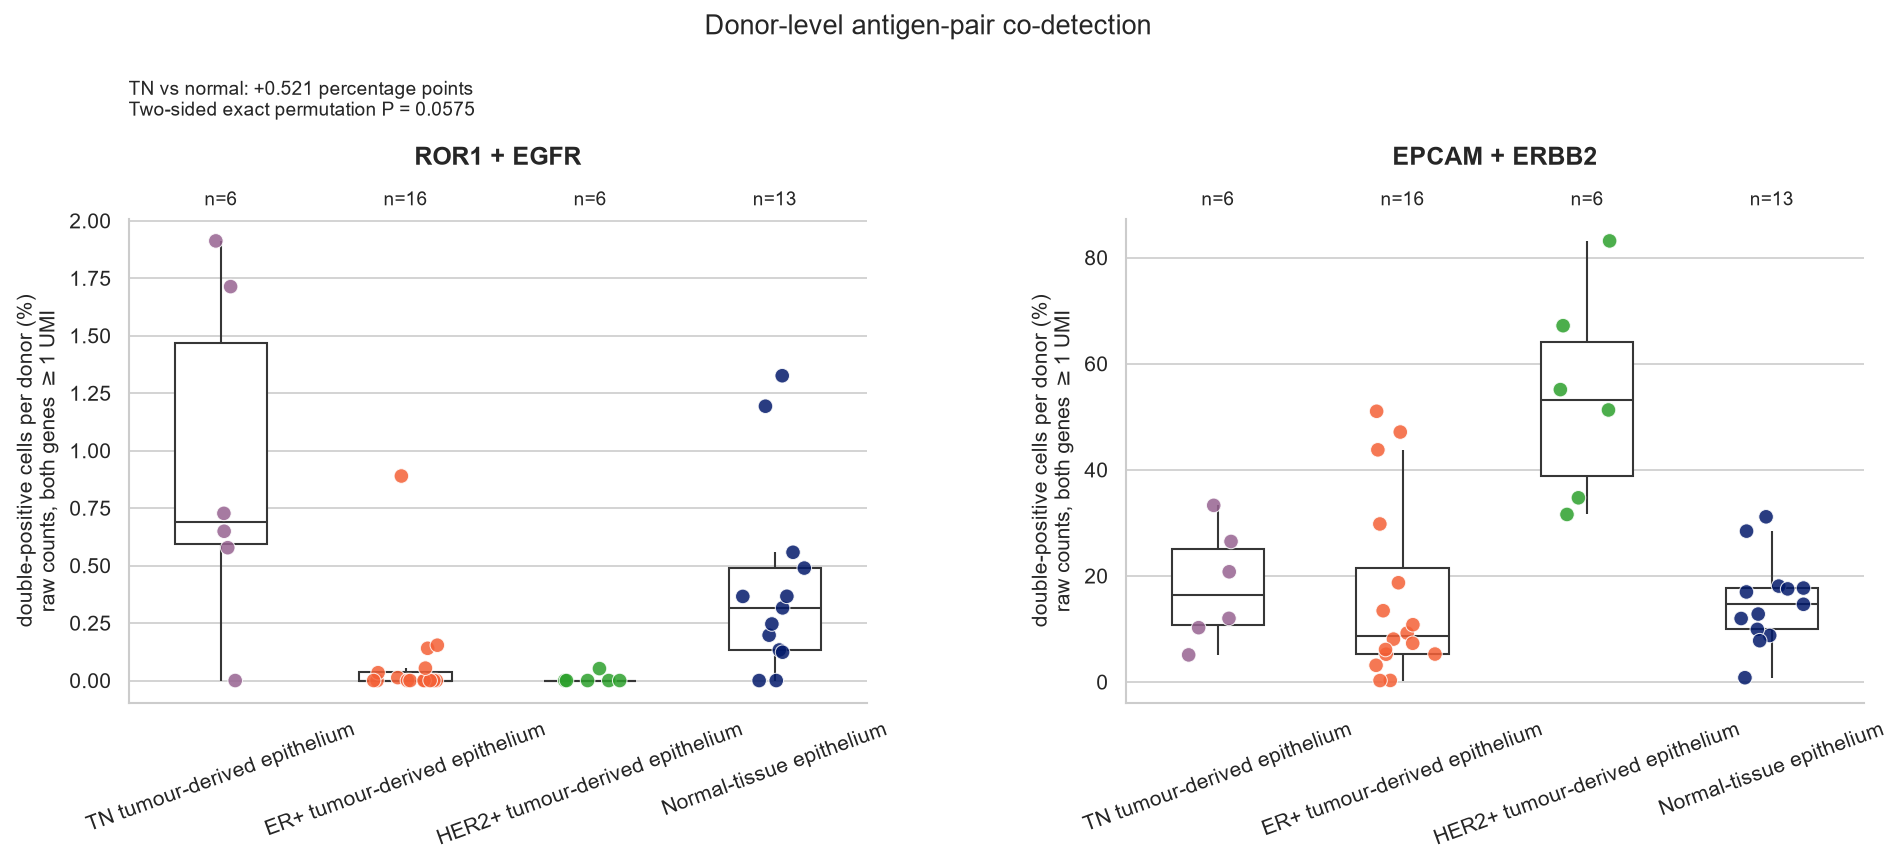

In [261]:
fig, axes = plt.subplots(1, len(antigen_pairs), figsize=(13, 6.2), sharey=False)
for ax, (gene_a, gene_b) in zip(np.atleast_1d(axes), antigen_pairs):
    pair = f"{gene_a}+{gene_b}"
    block = donor_levels[
        (donor_levels["pair"] == pair) & (donor_levels["min_umi"] == primary_min_umi)
    ]
    present = [g for g in group_order if g in set(block["group"])]
    sns.boxplot(
        data=block,
        x="group",
        y="prevalence",
        order=present,
        ax=ax,
        showfliers=False,
        width=0.5,
        boxprops={"facecolor": "white"},
        showcaps=False,
    )
    sns.stripplot(
        data=block,
        x="group",
        y="prevalence",
        order=present,
        ax=ax,
        hue="group",
        palette=group_palette,
        legend=False,
        size=7,
        alpha=0.85,
        jitter=0.18,
        linewidth=0.5,
        edgecolor="white",
    )
    for position, group in enumerate(present):
        donors = block.loc[block["group"] == group]
        ax.text(
            position,
            1.02,
            f"n={len(donors)}",
            ha="center",
            va="bottom",
            fontsize=9,
            transform=ax.get_xaxis_transform(),
        )
    ax.set_title(f"{gene_a} + {gene_b}", fontsize=12, fontweight="bold", pad=26)
    ax.set_xlabel("")
    ax.set_ylabel(
        f"double-positive cells per donor (%)\nraw counts, both genes $\\geq${primary_min_umi} UMI"
    )
    ax.tick_params(axis="x", rotation=20)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Donor-level antigen-pair co-detection", fontsize=13, y=0.99)
fig.text(
    0.09, 0.92,
    f"TN vs normal: {donor_inference['difference_pp']:+.3f} percentage points\n"
    f"Two-sided exact permutation P = {donor_inference['exact_permutation_p']:.4f}",
    ha="left", va="top", fontsize=9,
)
fig.subplots_adjust(left=0.09, right=0.98, bottom=0.25, top=0.77, wspace=0.35)
save_figure(fig, fig_dir / "donor_level_codetection", close=False, overwrite=False)
plt.show()


In [262]:
threshold_sensitivity = donor_levels[donor_levels["min_umi"] > primary_min_umi]


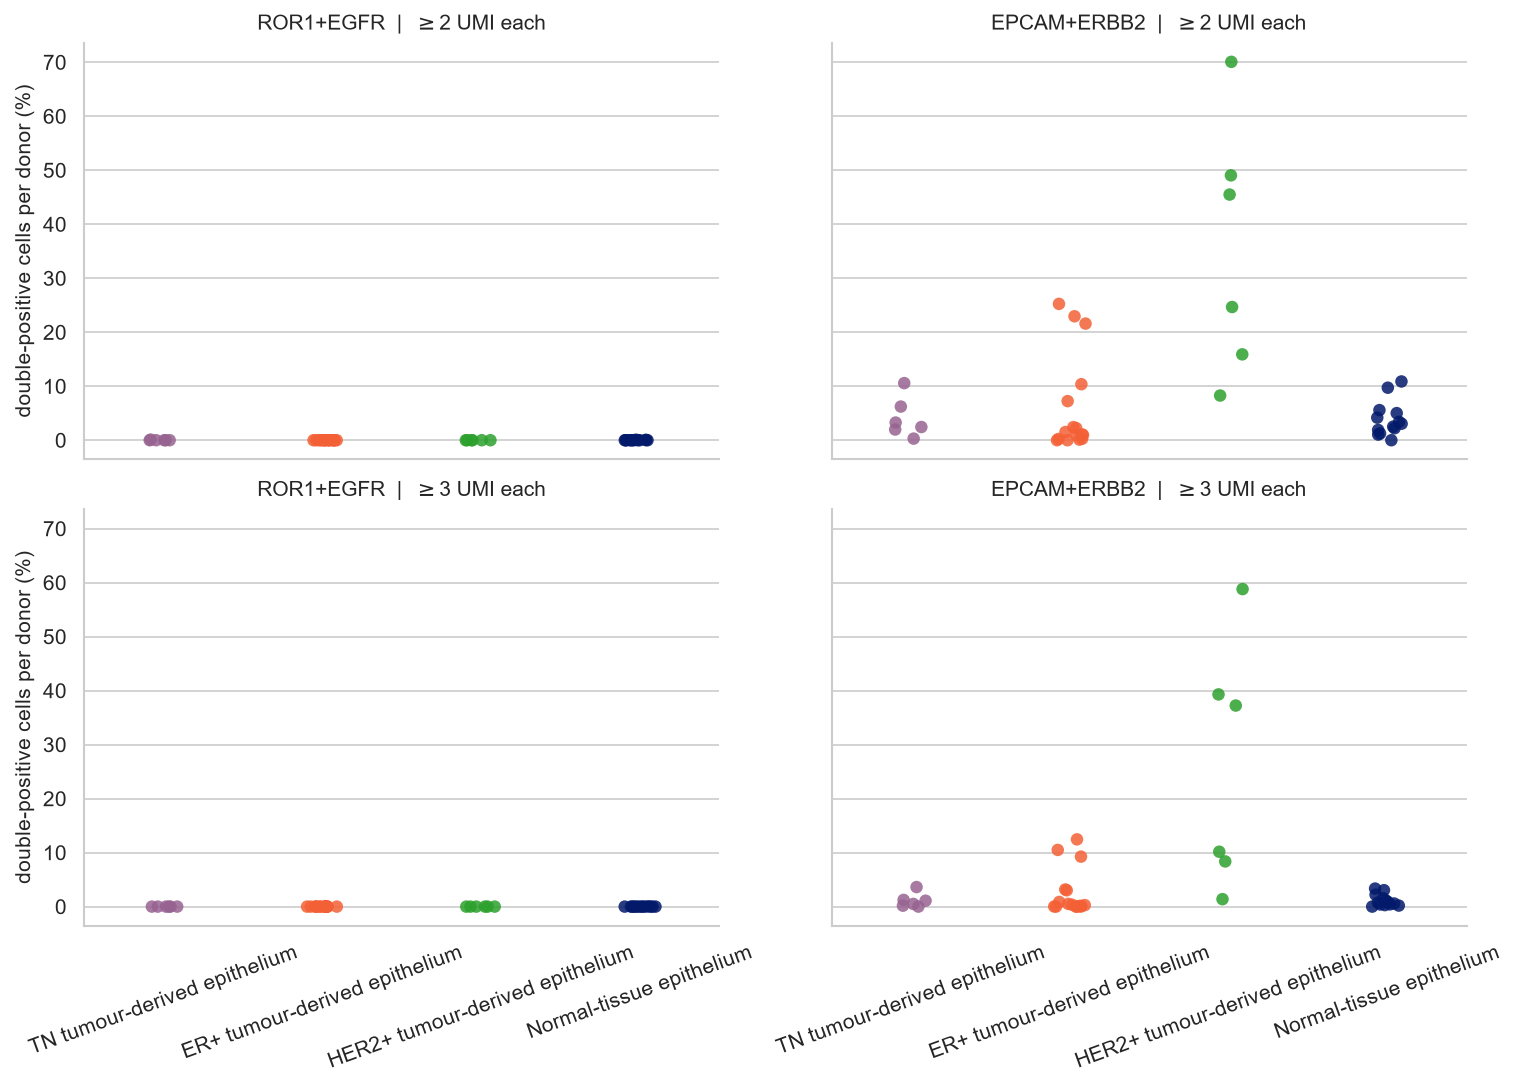

In [263]:
g = sns.catplot(
    data=threshold_sensitivity,
    x="group",
    y="prevalence",
    col="pair",
    row="min_umi",
    order=[g for g in group_order if g in set(threshold_sensitivity["group"])],
    hue="group",
    palette=group_palette,
    legend=False,
    kind="strip",
    height=3.4,
    aspect=1.5,
    size=6,
    alpha=0.85,
)

g.set_axis_labels("", "double-positive cells per donor (%)")

g.set_titles("{col_name}  |  $\\geq${row_name} UMI each")

for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=20)

save_figure(g.figure, fig_dir / "donor_codetection_umi_thresholds", close=False, overwrite=False)

plt.show()


In [264]:
def exact_difference_in_means(first, second):
    """Two-sided exact label permutation for a difference in donor means."""
    first = np.asarray(first, dtype=float)
    second = np.asarray(second, dtype=float)
    observed = first.mean() - second.mean()
    pooled = np.concatenate([first, second])
    indices = np.arange(len(pooled))
    null = np.array(
        [
            pooled[list(group)].mean()
            - pooled[np.setdiff1d(indices, group, assume_unique=True)].mean()
            for group in combinations(indices, len(first))
        ]
    )
    p_value = np.mean(np.abs(null) >= abs(observed) - 1e-12)
    return (observed, float(p_value), int(len(null)))


## Programme composition of co-detected cells

Donor-level prevalence pools cells across technical libraries. Donors with at
least 100 eligible cells contribute one observation each.


In [265]:
hallmark_order = list(epi.uns["meta_programme_hallmark_order"])


In [266]:
hallmark_palette = dict(zip(hallmark_order, epi.uns["meta_programme_hallmark_colors"]))


In [267]:
non_programme = [
    "low_activity",
    "unassigned_active",
    "mixed_active_but_ambiguous",
    "not_scored",
    "normal_tissue",
]


In [268]:
hallmark_palette.update(
    {
        "low_activity": "#BDBDBD",
        "unassigned_active": "#8C8C8C",
        "mixed_active_but_ambiguous": "#4D4D4D",
        "not_scored": "#D9D9D9",
        "normal_tissue": "#F0F0F0",
    }
)


In [269]:
state_key = "MP_programme_call"


In [270]:
observed_states = set(epi.obs[state_key].astype(str))


In [271]:
states = [s for s in hallmark_order + non_programme if s in observed_states]


In [272]:
assert set(condition_palette) == {"N", "ER+", "HER2+", "TN"}


In [273]:
panel_conditions = ["TN", "ER+", "HER2+", "N"]


In [274]:
def coexpression_composition(double_positive, scope_mask=None, conditions=None):
    counts = {}
    totals = {}
    percentages = {}
    if scope_mask is None:
        scope_mask = np.ones(epi.n_obs, bool)
    if conditions is None:
        conditions = panel_conditions
    state_values = epi.obs[state_key].astype(str).to_numpy()
    condition_values = epi.obs["condition"].astype(str).to_numpy()
    for condition in conditions:
        condition_mask = (condition_values == condition) & scope_mask
        both = condition_mask & double_positive
        totals[condition] = int(both.sum())
        percentages[condition] = 100 * both.sum() / condition_mask.sum()
        counts[condition] = {s: int((both & (state_values == s)).sum()) for s in states}
    return (counts, totals, percentages)


In [275]:
def coexpression_state_table(min_umi, scope):
    """Return cell-level programme counts without treating cells as replicates."""
    if scope == "all_epithelial":
        scope_mask = np.ones(epi.n_obs, dtype=bool)
        conditions_in_scope = panel_conditions
    elif scope == "tumour_derived":
        scope_mask = tumour_derived_only
        conditions_in_scope = [
            condition for condition in panel_conditions if condition != "N"
        ]
    elif scope == "tumour_derived_cnv_high":
        scope_mask = tumour_derived_cnv_high_only
        conditions_in_scope = [
            condition for condition in panel_conditions if condition != "N"
        ]
    elif scope == "tumour_derived_cnv_high_g1":
        scope_mask = tumour_derived_cnv_high_g1_only
        conditions_in_scope = [
            condition for condition in panel_conditions if condition != "N"
        ]
    else:
        raise ValueError(f"Unknown scope: {scope}")
    rows = []
    condition_values = epi.obs["condition"].astype(str).to_numpy()
    for gene_a, gene_b in antigen_pairs:
        double_positive = np.asarray(
            coexpression_group(epi, gene_a, gene_b, min_umi) == "Double positive"
        )
        counts, totals, percentages = coexpression_composition(
            double_positive, scope_mask, conditions_in_scope
        )
        for condition in conditions_in_scope:
            condition_mask = scope_mask & (condition_values == condition)
            rows.append(
                {
                    "pair": f"{gene_a}+{gene_b}",
                    "scope": scope,
                    "min_umi": min_umi,
                    "condition": condition,
                    "n_cells_in_scope": int(condition_mask.sum()),
                    "n_double_positive": totals[condition],
                    "pct_of_condition": percentages[condition],
                    **{f"n_{state}": counts[condition][state] for state in states},
                }
            )
    return pd.DataFrame(rows)


In [276]:
coexpression_panel_values = pd.concat(
    [
        coexpression_state_table(threshold, scope)
        for threshold in min_umi_sweep
        for scope in [
            "all_epithelial",
            "tumour_derived",
            "tumour_derived_cnv_high",
            "tumour_derived_cnv_high_g1",
        ]
    ],
    ignore_index=True,
)


In [277]:
coexpression_panel_values.to_csv(df_dir / "coexpression_panel_values.csv", index=False)


In [278]:
assert (
    coexpression_panel_values.filter(like="n_")
    .filter(regex="^n_(?!cells|double)")
    .sum(axis=1)
    == coexpression_panel_values["n_double_positive"]
).all()


In [279]:
display(
    coexpression_panel_values[
        [
            "pair",
            "scope",
            "min_umi",
            "condition",
            "n_cells_in_scope",
            "n_double_positive",
            "pct_of_condition",
        ]
    ].round(4)
)


,pair,scope,min_umi,condition,n_cells_in_scope,n_double_positive,pct_of_condition
0,ROR1+EGFR,all_epithelial,1,TN,26248,219,0.8343
1,ROR1+EGFR,all_epithelial,1,ER+,54256,13,0.0240
2,ROR1+EGFR,all_epithelial,1,HER2+,16515,2,0.0121
3,ROR1+EGFR,all_epithelial,1,N,26363,115,0.4362
4,EPCAM+ERBB2,all_epithelial,1,TN,26248,3623,13.8030
...,...,...,...,...,...,...,...
73,ROR1+EGFR,tumour_derived_cnv_high_g1,3,ER+,7117,0,0.0000
74,ROR1+EGFR,tumour_derived_cnv_high_g1,3,HER2+,3073,0,0.0000
75,EPCAM+ERBB2,tumour_derived_cnv_high_g1,3,TN,3155,19,0.6022
76,EPCAM+ERBB2,tumour_derived_cnv_high_g1,3,ER+,7117,239,3.3582


### Cell-cycle association

Cell Cycle being the largest class among double positives is a statement about their composition, not about enrichment. The primary population-level comparison below is restricted to TN tumour-derived epithelium and pairs each donor's double-positive cells with the remaining programme-scored tumour-derived epithelial cells from that donor. A secondary CMH analysis estimates the cell-level association conditional on the observed donors; it is reported separately because cells do not replace donors as biological replicates.

In [280]:
tn_tumour_derived = tumour_derived_only & (condition_values == "TN")


In [281]:
state_values = epi.obs[state_key].astype(str).to_numpy()


In [282]:
programme_scored = ~np.isin(state_values, ["normal_tissue", "not_scored"])


In [283]:
ror1_egfr_double_positive = (raw_counts(epi, "ROR1") >= primary_min_umi) & (
    raw_counts(epi, "EGFR") >= primary_min_umi
)


In [284]:
tn_scored_tumour_derived = (
    tumour_derived_only & (condition_values == "TN") & programme_scored
)


In [285]:
rows = []


In [286]:
for donor in np.unique(patient_values[tn_scored_tumour_derived]):
    in_donor = tn_scored_tumour_derived & (patient_values == donor)
    positive = in_donor & ror1_egfr_double_positive
    remainder = in_donor & ~ror1_egfr_double_positive
    rows.append(
        {
            "donor": donor,
            "n_double_positive": int(positive.sum()),
            "n_other_tumour": int(remainder.sum()),
            "cell_cycle_in_double_positive": (
                100 * (state_values[positive] == "Cell Cycle").mean()
                if positive.sum()
                else np.nan
            ),
            "cell_cycle_in_other": (
                100 * (state_values[remainder] == "Cell Cycle").mean()
                if remainder.sum()
                else np.nan
            ),
        }
    )


In [287]:
cell_cycle_by_donor = pd.DataFrame(rows)


In [288]:
cell_cycle_by_donor["difference_pp"] = (
    cell_cycle_by_donor["cell_cycle_in_double_positive"]
    - cell_cycle_by_donor["cell_cycle_in_other"]
)


In [289]:
cell_cycle_by_donor["eligible"] = (
    cell_cycle_by_donor["n_double_positive"] >= min_double_positive_cells
)


In [290]:
cell_cycle_by_donor.to_csv(df_dir / "coexpression_cell_cycle_by_donor.csv", index=False)


In [291]:
display(cell_cycle_by_donor.round(1))


,donor,n_double_positive,n_other_tumour,cell_cycle_in_double_positive,cell_cycle_in_other,difference_pp,eligible
0,MH0126,7,1071,28.6,22.8,5.8,True
1,MH0131,0,4846,NaN,8.0,NaN,False
2,MH0135,70,12043,60.0,46.2,13.8,True
3,MH0177,6,819,16.7,16.7,-0.1,True
4,MH4031,90,4616,46.7,33.2,13.4,True
5,Tum0554,45,2581,44.4,25.6,18.8,True


In [292]:
paired = (
    cell_cycle_by_donor.loc[cell_cycle_by_donor["eligible"], "difference_pp"]
    .dropna()
    .to_numpy()
)


In [293]:
nonzero = paired[paired != 0]


In [294]:
cell_cycle_enrichment = {
    "donors_examined": int(len(cell_cycle_by_donor)),
    "min_double_positive_cells": int(min_double_positive_cells),
    "eligible_donors": int(len(paired)),
    "donors_positive": int((paired > 0).sum()),
    "donors_negative": int((paired < 0).sum()),
    "donors_tied": int((paired == 0).sum()),
    "sign_test_denominator": int(len(nonzero)),
    "median_difference_pp": float(np.median(paired)) if len(paired) else np.nan,
    "sign_test_p": (
        float(binomtest(int((nonzero > 0).sum()), len(nonzero)).pvalue)
        if len(nonzero)
        else np.nan
    ),
    "smallest_attainable_p": (
        float(binomtest(len(nonzero), len(nonzero)).pvalue) if len(nonzero) else np.nan
    ),
}


In [295]:
epi.uns["coexpression_cell_cycle"] = cell_cycle_enrichment


In [296]:
display(cell_cycle_enrichment)


{'donors_examined': 6,
 'min_double_positive_cells': 5,
 'eligible_donors': 5,
 'donors_positive': 4,
 'donors_negative': 1,
 'donors_tied': 0,
 'sign_test_denominator': 5,
 'median_difference_pp': 13.434430964760246,
 'sign_test_p': 0.375,
 'smallest_attainable_p': 0.0625}

In [297]:
rows = []


In [298]:
for threshold in [1, 5, 10, 20]:
    difference = cell_cycle_by_donor.loc[
        cell_cycle_by_donor["n_double_positive"] >= threshold, "difference_pp"
    ].dropna()
    nonzero = difference[difference != 0]
    rows.append(
        {
            "min_double_positive_cells": threshold,
            "eligible_donors": len(difference),
            "donors_positive": int((difference > 0).sum()),
            "donors_negative": int((difference < 0).sum()),
            "donors_tied": int((difference == 0).sum()),
            "sign_test_denominator": len(nonzero),
            "median_difference_pp": difference.median() if len(difference) else np.nan,
            "sign_test_p": (
                binomtest(int((nonzero > 0).sum()), len(nonzero)).pvalue
                if len(nonzero)
                else np.nan
            ),
            "smallest_attainable_p": (
                binomtest(len(nonzero), len(nonzero)).pvalue if len(nonzero) else np.nan
            ),
        }
    )


In [299]:
eligibility_sweep = pd.DataFrame(rows)


In [300]:
eligibility_sweep.to_csv(
    df_dir / "coexpression_cell_cycle_eligibility_sweep.csv", index=False
)


In [301]:
display(eligibility_sweep.round(3))


,min_double_positive_cells,eligible_donors,donors_positive,donors_negative,donors_tied,sign_test_denominator,median_difference_pp,sign_test_p,smallest_attainable_p
0,1,5,4,1,0,5,13.434,0.375,0.062
1,5,5,4,1,0,5,13.434,0.375,0.062
2,10,3,3,0,0,3,13.757,0.250,0.250
3,20,3,3,0,0,3,13.757,0.250,0.250


### Conditional cell-level programme association

The donor sign test above is the primary test of generalisation across tumours.
The CMH analysis asks a narrower question: within the eligible TN tumours, are
double-positive cells more likely than the remaining tumour-derived epithelial cells to carry
each of the 13 biological programme classes? Low-activity and ambiguous cells
remain in the reference denominator but are not treated as additional
biological hypotheses. Holm correction is applied across all 13 classes. A
class absent from the analysed TN cells is retained with p = 1 and an undefined
odds ratio rather than being removed from the testing family.

This is conditional cell-level evidence within the observed donors, not a
substitute for donor-level replication. Library-depth stratification is
reported separately as a sensitivity analysis.

In [302]:
sample_values = epi.obs["sample"].astype(str).to_numpy()


In [303]:
patient_values = epi.obs["patient"].astype(str).to_numpy()


In [304]:
eligible_programme_donors = set(
    cell_cycle_by_donor.loc[cell_cycle_by_donor["eligible"], "donor"].astype(str)
)


In [305]:
observed_programmes = set(state_values[tn_scored_tumour_derived])


In [306]:
missing_programmes = [
    programme for programme in hallmark_order if programme not in observed_programmes
]


In [307]:
programmes = list(hallmark_order)


In [308]:
programme_rows = []


In [309]:
for programme in programmes:
    tables = []
    for donor in sorted(eligible_programme_donors):
        in_donor = tn_scored_tumour_derived & (patient_values == donor)
        positive = in_donor & ror1_egfr_double_positive
        remainder = in_donor & ~ror1_egfr_double_positive
        table = np.array(
            [
                [
                    int((state_values[positive] == programme).sum()),
                    int((state_values[positive] != programme).sum()),
                ],
                [
                    int((state_values[remainder] == programme).sum()),
                    int((state_values[remainder] != programme).sum()),
                ],
            ]
        )
        assert table.sum(axis=1).min() > 0
        tables.append(table)
    stacked = np.dstack(tables)
    pooled = stacked.sum(axis=2)
    n_programme_double_positive = int(pooled[0, 0])
    n_programme_remainder = int(pooled[1, 0])
    n_programme_total = n_programme_double_positive + n_programme_remainder
    n_cells_total = int(pooled.sum())
    testable = 0 < n_programme_total < n_cells_total
    common_odds_ratio = np.nan
    ci_low = np.nan
    ci_high = np.nan
    p_cmh = 1.0
    reason = "programme absent" if n_programme_total == 0 else "no outcome variation"
    if testable:
        fit = StratifiedTable(stacked)
        common_odds_ratio = float(fit.oddsratio_pooled)
        p_cmh = float(fit.test_null_odds().pvalue)
        reason = "tested"
        if np.isfinite(common_odds_ratio) and common_odds_ratio > 0:
            ci_low, ci_high = map(float, fit.oddsratio_pooled_confint())
        if not np.isfinite(p_cmh):
            p_cmh = 1.0
            testable = False
            reason = "no informative CMH contrast"
    programme_rows.append(
        {
            "programme": programme,
            "eligible_donors": len(tables),
            "min_double_positive_cells": min_double_positive_cells,
            "n_programme_double_positive": n_programme_double_positive,
            "n_programme_remainder": n_programme_remainder,
            "testable": bool(testable),
            "status": reason,
            "common_odds_ratio": common_odds_ratio,
            "ci_low": ci_low,
            "ci_high": ci_high,
            "p_cmh": p_cmh,
        }
    )


In [310]:
def inclusion_sensitivity(df_dir, annotation_dir, epi, min_donor_cells, exact_test):
    """Compare explicit manual inclusion choices using donor-level counts from 002."""
    out = Path(df_dir)
    counts = pd.read_csv(identity_counts_file)
    primary = counts.loc[counts.scope.eq("primary_epithelial") & counts.min_umi.eq(1)]
    expected = (
        epi.obs.groupby(["sample", "patient", "condition"], observed=True)
        .size()
        .rename("n_cells")
        .reset_index()
    )
    observed = primary[["sample", "patient", "condition", "n_cells"]]
    comparison = expected.merge(
        observed,
        on=["sample", "patient", "condition"],
        how="outer",
        suffixes=("_input", "_table"),
        indicator=True,
    )
    assert (
        comparison["_merge"].eq("both").all()
        and comparison.n_cells_input.eq(comparison.n_cells_table).all()
    ), "Refresh epithelial inclusion counts from the current 002 export."
    donor = (
        counts.groupby(["scope", "min_umi", "condition", "patient"], observed=True)[
            ["n_cells", "n_ror1", "n_egfr", "n_double_positive", "n_epcam_erbb2"]
        ]
        .sum()
        .reset_index()
    )
    donor["prevalence_pct"] = 100 * donor.n_double_positive / donor.n_cells
    donor.to_csv(out / "coexpression_epithelial_identity_by_donor.csv", index=False)
    rows = []
    for (scope, threshold), block in donor.groupby(["scope", "min_umi"], observed=True):
        eligible = block.loc[block.n_cells >= min_donor_cells]
        first = eligible.loc[eligible.condition.eq("TN"), "prevalence_pct"].to_numpy()
        second = eligible.loc[eligible.condition.eq("N"), "prevalence_pct"].to_numpy()
        if len(first) < 2 or len(second) < 2:
            raise ValueError("Too few donors for epithelial-inclusion sensitivity")
        difference, p_value, n_permutations = exact_test(first, second)
        rows.append(
            {
                "scope": scope,
                "min_umi": threshold,
                "min_donor_cells": min_donor_cells,
                "n_tn_donors": len(first),
                "n_normal_donors": len(second),
                "tn_mean_pct": first.mean(),
                "normal_mean_pct": second.mean(),
                "difference_pp": difference,
                "exact_permutation_p": p_value,
                "n_permutations": n_permutations,
                "interpretation": "exploratory inclusion sensitivity; not independent confirmatory tests",
            }
        )
    result = pd.DataFrame(rows)
    result.to_csv(out / "coexpression_epithelial_identity_sensitivity.csv", index=False)
    return result


In [311]:
epithelial_identity_sensitivity = inclusion_sensitivity(
    df_dir, annotation_dir, epi, min_donor_cells, exact_difference_in_means
)


In [312]:
display(epithelial_identity_sensitivity.round(4))


,scope,min_umi,min_donor_cells,n_tn_donors,n_normal_donors,tn_mean_pct,normal_mean_pct,difference_pp,exact_permutation_p,n_permutations,interpretation
0,including_uncertain_candidates,1,100,6,13,0.9301,0.4088,0.5213,0.0575,27132,exploratory inclusion sensitivity; not indepen...
1,including_uncertain_candidates,2,100,6,13,0.0190,0.0141,0.0050,0.8390,27132,exploratory inclusion sensitivity; not indepen...
2,primary_epithelial,1,100,6,13,0.9301,0.4088,0.5213,0.0575,27132,exploratory inclusion sensitivity; not indepen...
3,primary_epithelial,2,100,6,13,0.0190,0.0141,0.0050,0.8390,27132,exploratory inclusion sensitivity; not indepen...


In [313]:
epi.uns["epithelial_identity_sensitivity"] = {
    "source": "coexpression_epithelial_identity_sensitivity.csv",
    "method": "same donor-count pooling and exact difference in means as the primary contrast",
    "scope": "exploratory raw-count inclusion sensitivity; not programme composition",
}


In [314]:
programme_cmh = pd.DataFrame(programme_rows).sort_values("p_cmh").reset_index(drop=True)


In [315]:
assert programme_cmh["programme"].is_unique


In [316]:
assert set(programme_cmh["programme"]) == set(hallmark_order)


In [317]:
programme_cmh["p_holm"] = multipletests(programme_cmh["p_cmh"], method="holm")[1]


In [318]:
programme_cmh.to_csv(df_dir / "coexpression_programme_cmh.csv", index=False)


In [319]:
display(programme_cmh.round(4))


,programme,eligible_donors,min_double_positive_cells,n_programme_double_positive,n_programme_remainder,testable,status,common_odds_ratio,ci_low,ci_high,p_cmh,p_holm
0,Cell Cycle,5,5,107,8146,True,tested,1.8195,1.3855,2.3896,0.0000,0.0002
1,Interferon and MHC II,5,5,3,724,True,tested,0.2535,0.0816,0.7877,0.0086,0.1036
2,Neural Lineage,5,5,1,434,True,tested,0.2385,0.0335,1.6956,0.1180,1.0000
3,Oncogenic,5,5,0,55,True,tested,0.0000,NaN,NaN,0.3510,1.0000
4,Protein Regulation,5,5,3,197,True,tested,1.4459,0.4558,4.5864,0.5298,1.0000
5,Other Lineage,5,5,1,304,True,tested,0.5415,0.0750,3.9068,0.5367,1.0000
6,Mesenchymal,5,5,12,1286,True,tested,0.8279,0.4480,1.5299,0.5463,1.0000
7,Haematological Lineage,5,5,3,163,True,tested,1.3171,0.4110,4.2210,0.6404,1.0000
8,Respiration,5,5,0,28,True,tested,0.0000,NaN,NaN,0.6630,1.0000
9,Senescence,5,5,17,2987,True,tested,0.9309,0.5409,1.6022,0.7977,1.0000


In [320]:
depth_frame = pd.DataFrame(
    {
        "patient": patient_values[tn_scored_tumour_derived],
        "sample": sample_values[tn_scored_tumour_derived],
        "double_positive": ror1_egfr_double_positive[tn_scored_tumour_derived],
        "cell_cycle": state_values[tn_scored_tumour_derived] == "Cell Cycle",
        "log_library_size": np.log1p(
            epi.obs["total_counts"].to_numpy()[tn_scored_tumour_derived]
        ),
    }
)


In [321]:
depth_frame = depth_frame[depth_frame["patient"].isin(eligible_programme_donors)].copy()


In [322]:
depth_rows = []


In [323]:
for n_bins in [5, 10, 20]:
    tables = []
    for (patient, sample), donor_frame in depth_frame.groupby(
        ["patient", "sample"], observed=True
    ):
        donor_frame = donor_frame.copy()
        donor_frame["depth_bin"] = pd.qcut(
            donor_frame["log_library_size"], q=n_bins, labels=False, duplicates="drop"
        )
        for _, block in donor_frame.groupby("depth_bin", observed=True):
            if (
                block["double_positive"].nunique() < 2
                or block["cell_cycle"].nunique() < 2
            ):
                continue
            table = (
                pd.crosstab(block["double_positive"], block["cell_cycle"])
                .reindex(index=[True, False], columns=[True, False], fill_value=0)
                .to_numpy()
            )
            tables.append(table)
    fit = StratifiedTable(np.dstack(tables))
    ci_low, ci_high = fit.oddsratio_pooled_confint()
    depth_rows.append(
        {
            "depth_bins_per_donor": n_bins,
            "informative_strata": len(tables),
            "eligible_donors": len(eligible_programme_donors),
            "common_odds_ratio": float(fit.oddsratio_pooled),
            "ci_low": float(ci_low),
            "ci_high": float(ci_high),
            "p_cmh": float(fit.test_null_odds().pvalue),
        }
    )


In [324]:
cell_cycle_depth_sensitivity = pd.DataFrame(depth_rows)


In [325]:
cell_cycle_depth_sensitivity.to_csv(
    df_dir / "coexpression_cell_cycle_depth_sensitivity.csv", index=False
)


In [326]:
cell_cycle_row = programme_cmh.loc[programme_cmh["programme"] == "Cell Cycle"].iloc[0]


In [327]:
epi.uns["coexpression_cell_cycle"].update(
    {
        "conditional_cell_level_cmh_or": float(cell_cycle_row["common_odds_ratio"]),
        "conditional_cell_level_cmh_ci": [
            float(cell_cycle_row["ci_low"]),
            float(cell_cycle_row["ci_high"]),
        ],
        "conditional_cell_level_cmh_p": float(cell_cycle_row["p_cmh"]),
        "conditional_cell_level_cmh_holm_p": float(cell_cycle_row["p_holm"]),
        "depth_sensitivity": {
            str(int(row["depth_bins_per_donor"])): {
                key: (
                    int(value)
                    if key in ["informative_strata", "eligible_donors"]
                    else float(value)
                )
                for key, value in row.items()
                if key != "depth_bins_per_donor"
            }
            for row in depth_rows
        },
    }
)


In [328]:
display(cell_cycle_row.to_frame().T.round(4), cell_cycle_depth_sensitivity.round(4))


,programme,eligible_donors,min_double_positive_cells,n_programme_double_positive,n_programme_remainder,testable,status,common_odds_ratio,ci_low,ci_high,p_cmh,p_holm
0,Cell Cycle,5,5,107,8146,True,tested,1.81955,1.385463,2.389643,0.000012,0.00016


,depth_bins_per_donor,informative_strata,eligible_donors,common_odds_ratio,ci_low,ci_high,p_cmh
0,5,18,5,1.0286,0.7729,1.3687,0.8465
1,10,33,5,0.9878,0.7389,1.3206,0.9343
2,20,55,5,0.9928,0.7429,1.3267,0.9610


In [329]:
conditional_donors = eligible_donors[
    eligible_donors["group"].isin(
        ["TN tumour-derived epithelium", "Normal-tissue epithelium"]
    )
].copy()


In [330]:
conditional_donors["egfr_given_ror1_pct"] = np.where(
    conditional_donors["n_ror1"] > 0,
    100 * conditional_donors["n_double_positive"] / conditional_donors["n_ror1"],
    np.nan,
)


In [331]:
conditional_rows = []


In [332]:
for min_ror1_cells in [1, 5, 10]:
    eligible = conditional_donors[conditional_donors["n_ror1"] >= min_ror1_cells]
    tn = eligible.loc[
        eligible["group"] == "TN tumour-derived epithelium", "egfr_given_ror1_pct"
    ].to_numpy()
    normal_values = eligible.loc[
        eligible["group"] == "Normal-tissue epithelium", "egfr_given_ror1_pct"
    ].to_numpy()
    if len(tn) >= 2 and len(normal_values) >= 2:
        difference, p_value, n_permutations = exact_difference_in_means(
            tn, normal_values
        )
    else:
        difference, p_value, n_permutations = (np.nan, np.nan, 0)
    conditional_rows.append(
        {
            "min_ror1_positive_cells": min_ror1_cells,
            "tn_donors": len(tn),
            "normal_donors": len(normal_values),
            "tn_mean_pct": tn.mean() if len(tn) else np.nan,
            "normal_mean_pct": normal_values.mean() if len(normal_values) else np.nan,
            "difference_pp": difference,
            "exact_permutation_p": p_value,
            "n_permutations": n_permutations,
        }
    )


In [333]:
conditional_pair_sensitivity = pd.DataFrame(conditional_rows)


In [334]:
conditional_pair_sensitivity["p_holm"] = multipletests(
    conditional_pair_sensitivity["exact_permutation_p"], method="holm"
)[1]


In [335]:
conditional_donors.to_csv(
    df_dir / "egfr_detection_given_ror1_by_donor.csv", index=False
)


In [336]:
conditional_pair_sensitivity.to_csv(
    df_dir / "egfr_detection_given_ror1_sensitivity.csv", index=False
)


In [337]:
display(conditional_pair_sensitivity.round(4))


,min_ror1_positive_cells,tn_donors,normal_donors,tn_mean_pct,normal_mean_pct,difference_pp,exact_permutation_p,n_permutations,p_holm
0,1,6,12,25.3044,48.2035,-22.8991,0.0301,18564,0.048
1,5,5,8,30.3653,53.5553,-23.1900,0.0140,1287,0.042
2,10,5,7,30.3653,51.6822,-21.3169,0.0240,792,0.048


In [338]:
primary_donors = eligible_donors[
    eligible_donors["group"].isin(
        ["TN tumour-derived epithelium", "Normal-tissue epithelium"]
    )
].copy()


In [339]:
normal_values = primary_donors.loc[
    primary_donors["group"] == "Normal-tissue epithelium", "prevalence"
].to_numpy()


In [340]:
loo_rows = []


In [341]:
tn_block = primary_donors[primary_donors["group"] == "TN tumour-derived epithelium"]


In [342]:
for omitted in [None, *tn_block["patient"].astype(str)]:
    retained = tn_block if omitted is None else tn_block[tn_block["patient"] != omitted]
    difference, p_value, n_permutations = exact_difference_in_means(
        retained["prevalence"].to_numpy(), normal_values
    )
    loo_rows.append(
        {
            "omitted_tn_donor": "none" if omitted is None else omitted,
            "tn_donors": len(retained),
            "normal_donors": len(normal_values),
            "difference_pp": difference,
            "exact_permutation_p": p_value,
            "n_permutations": n_permutations,
        }
    )


In [343]:
leave_one_tn_out = pd.DataFrame(loo_rows)


In [344]:
tn_concentration = tn_block[
    ["patient", "n_cells", "n_ror1", "n_egfr", "n_double_positive", "prevalence"]
].copy()


In [345]:
tn_concentration["share_of_tn_double_positive_pct"] = (
    100
    * tn_concentration["n_double_positive"]
    / tn_concentration["n_double_positive"].sum()
)


In [346]:
tn_concentration = tn_concentration.sort_values("n_double_positive", ascending=False)


In [347]:
leave_one_tn_out.to_csv(df_dir / "ror1_egfr_leave_one_tn_donor_out.csv", index=False)


In [348]:
tn_concentration.to_csv(df_dir / "ror1_egfr_tn_donor_concentration.csv", index=False)


In [349]:
display(leave_one_tn_out.round(4))


,omitted_tn_donor,tn_donors,normal_donors,difference_pp,exact_permutation_p,n_permutations
0,none,6,13,0.5213,0.0575,27132
1,MH0126,5,13,0.5775,0.0495,8568
2,MH0131,5,13,0.7073,0.0127,8568
3,MH0135,5,13,0.5917,0.0437,8568
4,MH0177,5,13,0.5619,0.0533,8568
5,MH4031,5,13,0.3248,0.2150,8568
6,Tum0554,5,13,0.3646,0.1844,8568


In [350]:
display(tn_concentration.round(3))


,patient,n_cells,n_ror1,n_egfr,n_double_positive,prevalence,share_of_tn_double_positive_pct
39,MH4031,4706,401,878,90,1.912,41.284
37,MH0135,12113,286,2528,70,0.578,32.110
41,Tum0554,2626,104,478,45,1.714,20.642
35,MH0126,1078,29,118,7,0.649,3.211
38,MH0177,825,16,87,6,0.727,2.752
36,MH0131,4846,4,88,0,0.000,0.000


## Detected-gene sensitivity



The primary QC pipeline does not impose a universal 500-gene threshold because
sample-adaptive QC was used. This sensitivity table checks whether excluding
cells with fewer than 500 detected genes changes the antigen conclusions.

In [351]:
gene_complexity = epi.obs["n_genes_by_counts"].to_numpy()


In [352]:
condition_values = epi.obs["condition"].astype(str).to_numpy()


In [353]:
ror1_count = raw_counts(epi, "ROR1")


In [354]:
egfr_count = raw_counts(epi, "EGFR")


In [355]:
double_positive = (ror1_count >= primary_min_umi) & (egfr_count >= primary_min_umi)


In [356]:
complexity_rows = []


In [357]:
for condition in conditions:
    in_condition = condition_values == condition
    for minimum_genes in [0, 500]:
        retained = in_condition & (gene_complexity >= minimum_genes)
        ror1_positive = retained & (ror1_count >= primary_min_umi)
        complexity_rows.append(
            {
                "condition": condition,
                "minimum_detected_genes": minimum_genes,
                "n_cells": int(retained.sum()),
                "n_ror1_positive": int(ror1_positive.sum()),
                "n_double_positive": int((retained & double_positive).sum()),
                "double_positive_pct": 100 * double_positive[retained].mean(),
                "egfr_given_ror1_pct": (
                    100
                    * (ror1_positive & (egfr_count >= primary_min_umi)).sum()
                    / ror1_positive.sum()
                    if ror1_positive.sum()
                    else np.nan
                ),
            }
        )


In [358]:
complexity_sensitivity = pd.DataFrame(complexity_rows)


In [359]:
complexity_sensitivity.to_csv(df_dir / "antigen_min_genes_sensitivity.csv", index=False)


In [360]:
low_complexity_double_positive = pd.DataFrame(
    [
        {
            "cells_below_500_genes": int((gene_complexity < 500).sum()),
            "double_positive_below_500_genes": int(
                ((gene_complexity < 500) & double_positive).sum()
            ),
        }
    ]
)


In [361]:
low_complexity_double_positive.to_csv(
    df_dir / "antigen_low_complexity_double_positive.csv", index=False
)


In [362]:
display(complexity_sensitivity.round(4))


,condition,minimum_detected_genes,n_cells,n_ror1_positive,n_double_positive,double_positive_pct,egfr_given_ror1_pct
0,N,0,26363,217,115,0.4362,52.9954
1,N,500,24669,215,115,0.4662,53.4884
2,ER+,0,54256,67,13,0.0240,19.4030
3,ER+,500,45427,63,13,0.0286,20.6349
4,HER2+,0,16515,18,2,0.0121,11.1111
5,HER2+,500,15019,18,2,0.0133,11.1111
6,TN,0,26248,841,219,0.8343,26.0404
7,TN,500,25058,840,219,0.8740,26.0714


In [363]:
display(low_complexity_double_positive)


,cells_below_500_genes,double_positive_below_500_genes
0,13209,0


## Save

Retained-doublet-score sensitivity. Exclude cells above the within-sample singlet score q95 or q90; retain the same raw-count thresholds and donor eligibility. Scores are not calibrated across samples. Programme calls are held fixed after filtering; this is not a new scoring run or ambient-RNA correction.

In [364]:
def check_donor_profiles(obs, calls, categories):
    frame = obs.loc[
        calls.index, ["sample", "patient", "condition", "analysis_unit"]
    ].copy()
    frame["call"] = calls.astype(str)
    counts = frame.groupby("sample", observed=True).size()
    frame = frame[frame["sample"].isin(counts[counts >= 100].index)]
    sample = pd.crosstab(
        [frame["sample"], frame.analysis_unit, frame.condition],
        frame.call,
        normalize="index",
    )
    sample = sample.reindex(columns=categories, fill_value=0).reset_index()
    profiles = (
        sample.groupby(["analysis_unit", "condition"], observed=True)[categories]
        .mean()
        .reset_index()
    )
    if not np.allclose(profiles[categories].sum(axis=1), 1):
        raise ValueError("Incomplete programme composition.")
    return profiles


In [365]:
def check_exact_difference(first, second):
    first, second = (np.asarray(first, float), np.asarray(second, float))
    if min(len(first), len(second)) == 0 or not np.isfinite(np.r_[first, second]).all():
        raise ValueError("Both donor groups must be non-empty and finite.")
    pooled = np.r_[first, second]
    selected = np.asarray(list(itertools.combinations(range(len(pooled)), len(first))))
    sums = pooled[selected].sum(axis=1)
    null = sums / len(first) - (pooled.sum() - sums) / len(second)
    difference = float(first.mean() - second.mean())
    return (
        difference,
        float((np.abs(null) >= abs(difference) - 1e-12).mean()),
        len(null),
    )


In [366]:
def check_profile_test(profiles, categories, seed=0, permutations=9999):
    """Permutation of independent donor labels on Hellinger profiles."""
    values = np.sqrt(profiles[categories].to_numpy(float))
    labels = profiles["condition"].astype(str).to_numpy()
    levels = np.unique(labels)
    if len(levels) < 2 or any(((labels == level).sum() < 2 for level in levels)):
        return {"n_units": len(labels), "r_squared": np.nan, "p_permutation": np.nan}
    total = float(np.sum((values - values.mean(axis=0)) ** 2))

    def between(assignments):
        result = np.zeros(len(assignments))
        for level in levels:
            membership = assignments == level
            sums = membership.astype(float) @ values
            result += np.sum(sums * sums, axis=1) / membership.sum(axis=1)
        return result - len(values) * np.sum(values.mean(axis=0) ** 2)

    observed = between(labels[None, :])[0]
    rng = np.random.default_rng(seed)
    shuffled = np.stack([rng.permutation(labels) for _ in range(permutations)])
    null = between(shuffled)
    return {
        "n_units": len(labels),
        "r_squared": observed / total,
        "p_permutation": (1 + (null >= observed - 1e-12).sum()) / (permutations + 1),
    }


In [367]:
repository = notebook_dir


In [368]:
check_dir = run_dir / "publication_checks"


In [369]:
check_dir.mkdir(parents=True, exist_ok=True)


In [370]:
doublet_obs = epi.obs.copy()


In [371]:
if (
    doublet_obs.doublet_score.isna().any()
    or not doublet_obs.doublet_class.astype(str).eq("singlet").all()
):
    raise ValueError("This check expects retained singlets with finite doublet scores.")


In [372]:
doublet_ror1 = epi[:, "ROR1"].layers["counts"].toarray().ravel()


In [373]:
doublet_egfr = epi[:, "EGFR"].layers["counts"].toarray().ravel()


In [374]:
doublet_summaries, doublet_donor_rows, doublet_cutoffs, doublet_programme_rows = (
    [],
    [],
    [],
    [],
)


In [375]:
doublet_scored = ~doublet_obs.MP_programme_call.astype(str).isin(
    ["not_scored", "normal_tissue"]
)


In [376]:
doublet_categories = list(epi.uns["meta_programme_hallmark_order"]) + [
    "low_activity",
    "mixed_active_but_ambiguous",
    "unassigned_active",
]


In [377]:
for doublet_quantile in (1.0, 0.95, 0.9):
    doublet_limits = doublet_obs.groupby(
        "sample", observed=True
    ).doublet_score.quantile(doublet_quantile)
    doublet_keep = doublet_obs.doublet_score.le(
        doublet_obs["sample"].map(doublet_limits).astype(float)
    ).to_numpy()
    for doublet_sample, doublet_limit in doublet_limits.items():
        doublet_mask = doublet_obs["sample"].eq(doublet_sample).to_numpy()
        doublet_cutoffs.append(
            {
                "retained_score_quantile": doublet_quantile,
                "sample": doublet_sample,
                "score_cutoff": doublet_limit,
                "n_before": int(doublet_mask.sum()),
                "n_after": int((doublet_mask & doublet_keep).sum()),
            }
        )
    for doublet_min_umi in (1, 2):
        doublet_frame = doublet_obs.loc[doublet_keep, ["condition", "patient"]].copy()
        doublet_frame["double_positive"] = (
            (doublet_ror1 >= doublet_min_umi) & (doublet_egfr >= doublet_min_umi)
        )[doublet_keep]
        doublet_donors = (
            doublet_frame.groupby(["condition", "patient"], observed=True)
            .double_positive.agg(["size", "sum"])
            .reset_index()
        )
        doublet_donors = doublet_donors[doublet_donors["size"] >= 100].copy()
        doublet_donors["prevalence"] = (
            100 * doublet_donors["sum"] / doublet_donors["size"]
        )
        doublet_donors["retained_score_quantile"], doublet_donors["min_umi"] = (
            doublet_quantile,
            doublet_min_umi,
        )
        doublet_donor_rows.append(doublet_donors)
        doublet_tn = doublet_donors.loc[doublet_donors.condition.eq("TN"), "prevalence"]
        doublet_normal = doublet_donors.loc[
            doublet_donors.condition.eq("N"), "prevalence"
        ]
        doublet_difference, doublet_p_value, doublet_n_perm = check_exact_difference(
            doublet_tn, doublet_normal
        )
        doublet_summaries.append(
            {
                "retained_score_quantile": doublet_quantile,
                "min_umi": doublet_min_umi,
                "tn_donors": len(doublet_tn),
                "normal_donors": len(doublet_normal),
                "difference_pp": doublet_difference,
                "exact_permutation_p": doublet_p_value,
                "n_permutations": doublet_n_perm,
            }
        )
    doublet_profiles = check_donor_profiles(
        doublet_obs,
        doublet_obs.loc[doublet_keep & doublet_scored, "MP_programme_call"],
        doublet_categories,
    )
    doublet_programme_rows.append(
        {
            "retained_score_quantile": doublet_quantile,
            **check_profile_test(doublet_profiles, doublet_categories),
        }
    )


In [378]:
pd.DataFrame(doublet_summaries).to_csv(
    check_dir / "doublet_score_codetection_sensitivity.csv", index=False
)


In [379]:
pd.concat(doublet_donor_rows).to_csv(
    check_dir / "doublet_score_donor_prevalence.csv", index=False
)


In [380]:
pd.DataFrame(doublet_cutoffs).to_csv(
    check_dir / "doublet_score_cutoffs.csv", index=False
)


In [381]:
pd.DataFrame(doublet_programme_rows).to_csv(
    check_dir / "doublet_score_programme_global.csv", index=False
)


In [382]:
doublet_prevalence, doublet_programmes = (
    pd.DataFrame(doublet_summaries),
    pd.DataFrame(doublet_programme_rows),
)


In [383]:
display(doublet_prevalence)


,retained_score_quantile,min_umi,tn_donors,normal_donors,difference_pp,exact_permutation_p,n_permutations
0,1.00,1,6,13,0.521307,0.057497,27132
1,1.00,2,6,13,0.004985,0.839009,27132
2,0.95,1,6,13,0.531974,0.045150,27132
3,0.95,2,6,13,0.005249,0.839009,27132
4,0.90,1,6,13,0.533559,0.040543,27132
5,0.90,2,6,13,0.005539,0.839009,27132


In [384]:
display(doublet_programmes)


,retained_score_quantile,n_units,r_squared,p_permutation
0,1.00,28,0.171916,0.0112
1,0.95,28,0.172203,0.0111
2,0.90,28,0.173239,0.0105


In [385]:
def stamp_gene_policy(adata, policy, stage, cell_cycle_scored=None):
    previous = dict(adata.uns.get("gene_policy", {}))
    previous.update(
        {"version": policy["version"], "sha256": policy["sha256"], "stage": stage}
    )
    if cell_cycle_scored is not None:
        previous["cell_cycle_scored"] = bool(cell_cycle_scored)
    adata.uns["gene_policy"] = previous


In [386]:
stamp_gene_policy(epi, gene_policy, "antigen_coexpression")


In [387]:
final_positive = {
    g: int((np.asarray(epi[:, g].layers["counts"].todense()).ravel() > 0).sum())
    for g in target_genes
}


In [388]:
assert final_positive == baseline_positive


In [389]:
out_path = save_dir / "epithelial_antigen_coexpression.h5ad"


In [390]:
tmp_path = out_path.with_suffix(".h5ad.tmp")


In [391]:
if out_path.exists():
    raise FileExistsError("Analysis output already exists; choose a new run_dir for a fresh analysis.")


In [392]:
epi.write_h5ad(tmp_path, compression="gzip")


In [393]:
os.replace(tmp_path, out_path)


In [394]:
display(out_path.name)


'epithelial_antigen_coexpression.h5ad'

In [395]:
display(epi)


AnnData object with n_obs × n_vars = 123382 × 27292
    obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'S_score', 'G2M_score', 'phase', 'doublet_score', 'doublet_class', 'batch', 'patient', 'scVI_leiden', 'sample_short', 'celltypist_reference_label', 'celltypist_reference_confidence', 'cl_annotation', 'epithelial_candidate', 'epithelial_uncertain', 'epithelial_primary', 'cnv_score', 'cnv_signal', 'tumour_derived', 'cnv_high', 'tumour_derived_cnv_high', 'g1_cell', 'tumour_derived_cnv_high_g1', 'specimen_origin', 'leiden_r0.5', 'leiden_r1', 'leiden_r1.2', 'leiden_r1.5', 'epi_leiden', 'epi_leiden_protected', 'epi_leiden_seed2', 'analysis_unit', 'MP_dominant_class', 'MP_programme_call', 'MP_relative_margin', 

In [396]:
check = sc.read_h5ad(out_path, backed="r")


In [397]:
assert check.n_obs == epi.n_obs


In [398]:
assert check.n_vars == epi.n_vars


In [399]:
del check


In [400]:
gc.collect()


960

In [401]:
session_info.show()


D:\Conda\envs\cap-rerun\Lib\site-packages\session_info\main.py:213: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  mod_version = _find_version(mod.__version__)
D:\Conda\envs\cap-rerun\Lib\site-packages\session_info\main.py:213: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  mod_version = _find_version(mod.__version__)
